In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028933.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028394.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027799.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028100.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027960.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028872.jpg
/kaggle/input/datasets/kmader/skin-

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is NOT available")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
Using device: cuda


In [4]:
import os

print("Available datasets:")
print(os.listdir("/kaggle/input"))

Available datasets:
['datasets']


In [5]:
import os

path = "/kaggle/input/datasets"

print("Inside /kaggle/input/datasets:")
for item in os.listdir(path):
    print(item)

Inside /kaggle/input/datasets:
kmader


In [6]:
import os

path = "/kaggle/input/datasets/kmader"

print("Inside kmader:")
for item in os.listdir(path):
    print(item)

Inside kmader:
skin-cancer-mnist-ham10000


In [7]:
import os

base_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

print("HAM10000 files/folders:")
for item in os.listdir(base_path):
    print(item)

HAM10000 files/folders:
hmnist_8_8_RGB.csv
hmnist_28_28_RGB.csv
HAM10000_images_part_1
ham10000_images_part_1
hmnist_8_8_L.csv
HAM10000_images_part_2
ham10000_images_part_2
hmnist_28_28_L.csv
HAM10000_metadata.csv


In [8]:
import pandas as pd

base_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

metadata_path = f"{base_path}/HAM10000_metadata.csv"

df = pd.read_csv(metadata_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [9]:
# -------------------------------
# 1. Check missing age values
# -------------------------------
print("Missing age before:", df["age"].isna().sum())

# Use the training median later.
# For now, use the known dataset median = 50.0
median_age = 50.0

df["age"] = df["age"].fillna(median_age)

# -------------------------------
# 2. Encode gender
# -------------------------------
gender_mapping = {
    "male": 0,
    "female": 1,
    "unknown": 2
}

df["sex_encoded"] = df["sex"].map(gender_mapping)

# -------------------------------
# 3. Lesion class mapping
# -------------------------------
lesion_mapping = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

df["lesion_label"] = df["dx"].map(lesion_mapping)

# -------------------------------
# 4. Binary classification
# -------------------------------
benign_classes = ["nv", "bkl", "df", "vasc"]
malignant_classes = ["mel", "bcc", "akiec"]

df["binary_label"] = df["dx"].apply(
    lambda x: 1 if x in malignant_classes else 0
)

# -------------------------------
# 5. Display results
# -------------------------------
print("\nMissing age after:", df["age"].isna().sum())

print("\nGender encoding:")
print(df[["sex", "sex_encoded"]].drop_duplicates())

print("\nLesion classes:")
print(df[["dx", "lesion_label"]].drop_duplicates().sort_values("lesion_label"))

print("\nBinary class distribution:")
print(df["binary_label"].value_counts().sort_index())

print("\nAge range:")
print(df["age"].min(), "to", df["age"].max())

Missing age before: 57

Missing age after: 0

Gender encoding:
         sex  sex_encoded
0       male            0
8     female            1
968  unknown            2

Lesion classes:
         dx  lesion_label
9687  akiec             0
2462    bcc             1
0       bkl             2
1095     df             3
1211    mel             4
64       nv             5
2320   vasc             6

Binary class distribution:
binary_label
0    8061
1    1954
Name: count, dtype: int64

Age range:
0.0 to 85.0


In [10]:
!pip install iterative-stratification -q

In [11]:
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# Get unique lesion IDs
# --------------------------------------------------
unique_lesions = df["lesion_id"].unique()

# --------------------------------------------------
# First split:
# 5230 lesions for training
# 2240 lesions for temporary set
# --------------------------------------------------
train_lesions, temp_lesions = train_test_split(
    unique_lesions,
    test_size=2240,
    random_state=42
)

# --------------------------------------------------
# Second split:
# 1120 validation lesions
# 1120 test lesions
# --------------------------------------------------
val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=1120,
    random_state=42
)

# --------------------------------------------------
# Create image-level dataframes
# --------------------------------------------------
train_df = df[df["lesion_id"].isin(train_lesions)].copy()
val_df = df[df["lesion_id"].isin(val_lesions)].copy()
test_df = df[df["lesion_id"].isin(test_lesions)].copy()

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# --------------------------------------------------
# Display sizes
# --------------------------------------------------
print("Train images      :", len(train_df))
print("Validation images :", len(val_df))
print("Test images       :", len(test_df))

print("\nUnique lesions:")
print("Train      :", train_df["lesion_id"].nunique())
print("Validation :", val_df["lesion_id"].nunique())
print("Test       :", test_df["lesion_id"].nunique())

Train images      : 6988
Validation images : 1512
Test images       : 1515

Unique lesions:
Train      : 5230
Validation : 1120
Test       : 1120


In [12]:
train_lesion_ids = set(train_df["lesion_id"])
val_lesion_ids = set(val_df["lesion_id"])
test_lesion_ids = set(test_df["lesion_id"])

print("LESION OVERLAP CHECK")
print("Train ∩ Validation :", len(train_lesion_ids & val_lesion_ids))
print("Train ∩ Test       :", len(train_lesion_ids & test_lesion_ids))
print("Validation ∩ Test  :", len(val_lesion_ids & test_lesion_ids))

print("\nTOTAL IMAGES")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))
print("Total      :", len(train_df) + len(val_df) + len(test_df))

LESION OVERLAP CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

TOTAL IMAGES
Train      : 6988
Validation : 1512
Test       : 1515
Total      : 10015


In [13]:
import glob
import os

# Find all images in both HAM10000 folders
image_files = (
    glob.glob(f"{base_path}/HAM10000_images_part_1/*.jpg") +
    glob.glob(f"{base_path}/HAM10000_images_part_2/*.jpg")
)

print("Total images found:", len(image_files))

# Create image_id -> image path dictionary
image_path_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

print("Image mappings:", len(image_path_map))

# Check whether every dataset image has a corresponding file
missing_images = [
    image_id for image_id in df["image_id"]
    if image_id not in image_path_map
]

print("Missing images:", len(missing_images))

# Show one example
sample_id = df.iloc[0]["image_id"]
print("\nExample:")
print("Image ID :", sample_id)
print("Path     :", image_path_map[sample_id])

Total images found: 10015
Image mappings: 10015
Missing images: 0

Example:
Image ID : ISIC_0027419
Path     : /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027419.jpg


In [14]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class MultiModalSkinDataset(Dataset):

    def __init__(self, df, image_path_map, transform=None):
        self.df = df.reset_index(drop=True)
        self.image_path_map = image_path_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # -----------------------------
        # Image
        # -----------------------------
        image_id = row["image_id"]
        image_path = self.image_path_map[image_id]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # -----------------------------
        # Age
        # -----------------------------
        age = torch.tensor(
            row["age"] / 100.0,
            dtype=torch.float32
        )

        # -----------------------------
        # Gender
        # -----------------------------
        gender = torch.tensor(
            row["sex_encoded"],
            dtype=torch.long
        )

        # -----------------------------
        # Labels
        # -----------------------------
        lesion_label = torch.tensor(
            row["lesion_label"],
            dtype=torch.long
        )

        binary_label = torch.tensor(
            row["binary_label"],
            dtype=torch.long
        )

        return (
            image,
            age,
            gender,
            lesion_label,
            binary_label
        )

In [15]:
from torchvision import transforms
from torch.utils.data import DataLoader

# -----------------------------------
# Image transformations
# -----------------------------------

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# -----------------------------------
# Create datasets
# -----------------------------------

train_dataset = MultiModalSkinDataset(
    train_df,
    image_path_map,
    transform=train_transform
)

val_dataset = MultiModalSkinDataset(
    val_df,
    image_path_map,
    transform=val_test_transform
)

test_dataset = MultiModalSkinDataset(
    test_df,
    image_path_map,
    transform=val_test_transform
)

# -----------------------------------
# Create DataLoaders
# -----------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

DataLoaders created successfully!
Train: 6988
Validation: 1512
Test: 1515


In [16]:
# Get one batch
images, ages, genders, lesion_labels, binary_labels = next(iter(train_loader))

print("Images shape        :", images.shape)
print("Ages shape          :", ages.shape)
print("Genders shape       :", genders.shape)
print("Lesion labels shape :", lesion_labels.shape)
print("Binary labels shape :", binary_labels.shape)

print("\nAge example:")
print(ages[:5])

print("\nGender example:")
print(genders[:5])

print("\nLesion labels:")
print(lesion_labels[:5])

print("\nBinary labels:")
print(binary_labels[:5])

# Check for invalid age values
print("\nAge contains NaN :", torch.isnan(ages).any().item())
print("Age contains Inf :", torch.isinf(ages).any().item())

Images shape        : torch.Size([32, 3, 224, 224])
Ages shape          : torch.Size([32])
Genders shape       : torch.Size([32])
Lesion labels shape : torch.Size([32])
Binary labels shape : torch.Size([32])

Age example:
tensor([0.4000, 0.4500, 0.6000, 0.7000, 0.5500])

Gender example:
tensor([0, 0, 0, 1, 0])

Lesion labels:
tensor([5, 5, 5, 4, 5])

Binary labels:
tensor([0, 0, 0, 1, 0])

Age contains NaN : False
Age contains Inf : False


In [17]:
import torch
import torch.nn as nn
from torchvision import models

# -----------------------------------
# Device
# -----------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# -----------------------------------
# Pretrained EfficientNet-B0
# -----------------------------------

backbone = models.efficientnet_b0(weights="DEFAULT")

# -----------------------------------
# Multimodal Model
# -----------------------------------

class MultiModalEfficientNet(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        # Image feature extractor
        self.features = backbone.features

        # EfficientNet-B0 output = 1280
        image_features = backbone.classifier[1].in_features

        # Metadata network
        self.metadata_net = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 32),
            nn.ReLU()
        )

        # Fusion layer
        self.fusion = nn.Sequential(
            nn.Linear(image_features + 32, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # 7-class lesion classification
        self.lesion_head = nn.Linear(256, 7)

        # Binary benign/malignant classification
        self.binary_head = nn.Linear(256, 2)

    def forward(self, image, age, gender):

        # -----------------------------
        # Image branch
        # -----------------------------
        x = self.features(image)

        x = torch.nn.functional.adaptive_avg_pool2d(
            x, 1
        )

        x = torch.flatten(x, 1)

        # -----------------------------
        # Metadata branch
        # -----------------------------
        metadata = torch.stack(
            [age, gender.float()],
            dim=1
        )

        metadata = self.metadata_net(metadata)

        # -----------------------------
        # Feature fusion
        # -----------------------------
        combined = torch.cat(
            [x, metadata],
            dim=1
        )

        combined = self.fusion(combined)

        # -----------------------------
        # Outputs
        # -----------------------------
        lesion_output = self.lesion_head(combined)

        binary_output = self.binary_head(combined)

        return lesion_output, binary_output


# -----------------------------------
# Create model
# -----------------------------------

model_mm = MultiModalEfficientNet(backbone).to(device)

print("\nModel created successfully!")
print("Device:", next(model_mm.parameters()).device)

Using device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 



Model created successfully!
Device: cuda:0


In [18]:
import torch
import torch.nn as nn

# -----------------------------------
# Calculate class weights
# -----------------------------------

# 7-class lesion weights
lesion_counts = train_df["lesion_label"].value_counts().sort_index()

lesion_weights = len(train_df) / (
    7 * lesion_counts
)

lesion_weights = torch.tensor(
    lesion_weights.values,
    dtype=torch.float32
).to(device)

# Binary class weights
binary_counts = train_df["binary_label"].value_counts().sort_index()

binary_weights = len(train_df) / (
    2 * binary_counts
)

binary_weights = torch.tensor(
    binary_weights.values,
    dtype=torch.float32
).to(device)

# -----------------------------------
# Loss functions
# -----------------------------------

lesion_criterion = nn.CrossEntropyLoss(
    weight=lesion_weights
)

binary_criterion = nn.CrossEntropyLoss(
    weight=binary_weights
)

# -----------------------------------
# Optimizer
# -----------------------------------

optimizer = torch.optim.Adam(
    model_mm.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print("Lesion class weights:")
print(lesion_weights)

print("\nBinary class weights:")
print(binary_weights)

print("\nOptimizer:")
print(optimizer)

Lesion class weights:
tensor([ 4.2480,  2.8121,  1.3601, 13.3105,  1.2881,  0.2111, 11.7445],
       device='cuda:0')

Binary class weights:
tensor([0.6214, 2.5597], device='cuda:0')

Optimizer:
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


In [19]:
import torch
import os
from tqdm import tqdm

# -----------------------------------
# Training settings
# -----------------------------------

num_epochs = 10

checkpoint_dir = "/kaggle/working/multimodal_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_model_path = os.path.join(
    checkpoint_dir,
    "best_multimodal_efficientnet.pth"
)

best_val_acc = 0.0

# -----------------------------------
# Training loop
# -----------------------------------

for epoch in range(num_epochs):

    # ================================
    # TRAINING
    # ================================
    model_mm.train()

    running_loss = 0.0
    correct_binary = 0
    total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs} - Train"
    )

    for images, ages, genders, lesion_labels, binary_labels in train_bar:

        images = images.to(device, non_blocking=True)
        ages = ages.to(device, non_blocking=True)
        genders = genders.to(device, non_blocking=True)
        lesion_labels = lesion_labels.to(device, non_blocking=True)
        binary_labels = binary_labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        # Forward pass
        lesion_output, binary_output = model_mm(
            images,
            ages,
            genders
        )

        # Losses
        lesion_loss = lesion_criterion(
            lesion_output,
            lesion_labels
        )

        binary_loss = binary_criterion(
            binary_output,
            binary_labels
        )

        total_loss = lesion_loss + binary_loss

        # Safety check
        if not torch.isfinite(total_loss):
            print("WARNING: Non-finite loss detected!")
            print("Lesion loss:", lesion_loss.item())
            print("Binary loss:", binary_loss.item())
            raise RuntimeError("Training stopped because loss became NaN/Inf.")

        # Backpropagation
        total_loss.backward()

        optimizer.step()

        # Statistics
        running_loss += total_loss.item()

        predictions = torch.argmax(
            binary_output,
            dim=1
        )

        correct_binary += (
            predictions == binary_labels
        ).sum().item()

        total += binary_labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_binary_acc = correct_binary / total

    # ================================
    # VALIDATION
    # ================================
    model_mm.eval()

    val_running_loss = 0.0
    val_correct_binary = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Val"
        )

        for images, ages, genders, lesion_labels, binary_labels in val_bar:

            images = images.to(device, non_blocking=True)
            ages = ages.to(device, non_blocking=True)
            genders = genders.to(device, non_blocking=True)
            lesion_labels = lesion_labels.to(device, non_blocking=True)
            binary_labels = binary_labels.to(device, non_blocking=True)

            lesion_output, binary_output = model_mm(
                images,
                ages,
                genders
            )

            lesion_loss = lesion_criterion(
                lesion_output,
                lesion_labels
            )

            binary_loss = binary_criterion(
                binary_output,
                binary_labels
            )

            total_loss = lesion_loss + binary_loss

            val_running_loss += total_loss.item()

            predictions = torch.argmax(
                binary_output,
                dim=1
            )

            val_correct_binary += (
                predictions == binary_labels
            ).sum().item()

            val_total += binary_labels.size(0)

    val_loss = val_running_loss / len(val_loader)
    val_binary_acc = val_correct_binary / val_total

    # ================================
    # PRINT RESULTS
    # ================================
    print(
        f"\nEpoch {epoch+1}/{num_epochs}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Binary Acc: {train_binary_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Binary Acc: {val_binary_acc:.4f}"
    )

    # ================================
    # SAVE EVERY EPOCH
    # ================================
    epoch_checkpoint = os.path.join(
        checkpoint_dir,
        f"checkpoint_epoch_{epoch+1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_mm.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_acc": best_val_acc,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_binary_acc": val_binary_acc
    }, epoch_checkpoint)

    # ================================
    # SAVE BEST MODEL
    # ================================
    if val_binary_acc > best_val_acc:

        best_val_acc = val_binary_acc

        torch.save(
            model_mm.state_dict(),
            best_model_path
        )

        print(
            f"⭐ Best model saved! "
            f"Validation Accuracy: {best_val_acc:.4f}"
        )

print("\nTraining completed!")
print(
    f"Best Validation Binary Accuracy: "
    f"{best_val_acc:.4f}"
)
print("Best model:", best_model_path)

Epoch 1/10 - Val: 100%|██████████| 48/48 [00:15<00:00,  3.04it/s]



Epoch 1/10
Train Loss: 1.9595 | Train Binary Acc: 0.7657
Val Loss: 1.2548 | Val Binary Acc: 0.8022
⭐ Best model saved! Validation Accuracy: 0.8022


Epoch 2/10 - Val: 100%|██████████| 48/48 [00:09<00:00,  5.00it/s]



Epoch 2/10
Train Loss: 1.1665 | Train Binary Acc: 0.8154
Val Loss: 1.1298 | Val Binary Acc: 0.7857


Epoch 3/10 - Val: 100%|██████████| 48/48 [00:08<00:00,  5.53it/s]


...


Epoch 8/10
Train Loss: 0.4416 | Train Binary Acc: 0.9227
Val Loss: 0.9793 | Val Binary Acc: 0.8611
⭐ Best model saved! Validation Accuracy: 0.8611


Epoch 9/10 - Val: 100%|██████████| 48/48 [00:08<00:00,  5.90it/s]



Epoch 9/10
Train Loss: 0.3759 | Train Binary Acc: 0.9367
Val Loss: 0.9117 | Val Binary Acc: 0.8783
⭐ Best model saved! Validation Accuracy: 0.8783


Epoch 10/10 - Val: 100%|██████████| 48/48 [00:08<00:00,  5.79it/s]


Epoch 10/10
Train Loss: 0.3384 | Train Binary Acc: 0.9468
Val Loss: 1.0742 | Val Binary Acc: 0.8439

Training completed!
Best Validation Binary Accuracy: 0.8783
Best model: /kaggle/working/multimodal_checkpoints/best_multimodal_efficientnet.pth


In [20]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# -----------------------------------
# Load best multimodal model
# -----------------------------------

best_model_path = "/kaggle/working/multimodal_checkpoints/best_multimodal_efficientnet.pth"

model_mm.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model_mm = model_mm.to(device)
model_mm.eval()

# -----------------------------------
# Store predictions and true labels
# -----------------------------------

binary_true = []
binary_pred = []

lesion_true = []
lesion_pred = []

# -----------------------------------
# Test evaluation
# -----------------------------------

with torch.no_grad():

    for images, ages, genders, lesion_labels, binary_labels in test_loader:

        images = images.to(device, non_blocking=True)
        ages = ages.to(device, non_blocking=True)
        genders = genders.to(device, non_blocking=True)

        lesion_output, binary_output = model_mm(
            images,
            ages,
            genders
        )

        # Binary predictions
        binary_predictions = torch.argmax(
            binary_output,
            dim=1
        )

        # Lesion predictions
        lesion_predictions = torch.argmax(
            lesion_output,
            dim=1
        )

        binary_true.extend(
            binary_labels.numpy()
        )

        binary_pred.extend(
            binary_predictions.cpu().numpy()
        )

        lesion_true.extend(
            lesion_labels.numpy()
        )

        lesion_pred.extend(
            lesion_predictions.cpu().numpy()
        )

# -----------------------------------
# Binary metrics
# -----------------------------------

binary_accuracy = accuracy_score(
    binary_true,
    binary_pred
)

binary_precision = precision_score(
    binary_true,
    binary_pred,
    average="weighted",
    zero_division=0
)

binary_recall = recall_score(
    binary_true,
    binary_pred,
    average="weighted",
    zero_division=0
)

binary_f1 = f1_score(
    binary_true,
    binary_pred,
    average="weighted",
    zero_division=0
)

print("=" * 50)
print("MULTIMODAL EFFICIENTNET-B0")
print("BINARY TEST RESULTS")
print("=" * 50)

print(f"Accuracy  : {binary_accuracy:.4f}")
print(f"Precision : {binary_precision:.4f}")
print(f"Recall    : {binary_recall:.4f}")
print(f"F1 Score  : {binary_f1:.4f}")

# -----------------------------------
# Binary confusion matrix
# -----------------------------------

print("\nBinary Confusion Matrix:")
print(confusion_matrix(binary_true, binary_pred))

# -----------------------------------
# Binary classification report
# -----------------------------------

print("\nBinary Classification Report:")
print(
    classification_report(
        binary_true,
        binary_pred,
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)

# -----------------------------------
# 7-class lesion metrics
# -----------------------------------

lesion_accuracy = accuracy_score(
    lesion_true,
    lesion_pred
)

lesion_precision = precision_score(
    lesion_true,
    lesion_pred,
    average="weighted",
    zero_division=0
)

lesion_recall = recall_score(
    lesion_true,
    lesion_pred,
    average="weighted",
    zero_division=0
)

lesion_f1 = f1_score(
    lesion_true,
    lesion_pred,
    average="weighted",
    zero_division=0
)

print("=" * 50)
print("7-CLASS LESION TEST RESULTS")
print("=" * 50)

print(f"Accuracy  : {lesion_accuracy:.4f}")
print(f"Precision : {lesion_precision:.4f}")
print(f"Recall    : {lesion_recall:.4f}")
print(f"F1 Score  : {lesion_f1:.4f}")

# -----------------------------------
# 7-class classification report
# -----------------------------------

class_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("\n7-Class Classification Report:")
print(
    classification_report(
        lesion_true,
        lesion_pred,
        labels=list(range(7)),
        target_names=class_names,
        zero_division=0
    )
)

MULTIMODAL EFFICIENTNET-B0
BINARY TEST RESULTS
Accuracy  : 0.8680
Precision : 0.8740
Recall    : 0.8680
F1 Score  : 0.8706

Binary Confusion Matrix:
[[1124  115]
 [  85  191]]

Binary Classification Report:
              precision    recall  f1-score   support

      Benign       0.93      0.91      0.92      1239
   Malignant       0.62      0.69      0.66       276

    accuracy                           0.87      1515
   macro avg       0.78      0.80      0.79      1515
weighted avg       0.87      0.87      0.87      1515

7-CLASS LESION TEST RESULTS
Accuracy  : 0.7934
Precision : 0.8250
Recall    : 0.7934
F1 Score  : 0.8024

7-Class Classification Report:
              precision    recall  f1-score   support

       akiec       0.60      0.64      0.62        45
         bcc       0.58      0.83      0.68        78
         bkl       0.55      0.80      0.65       186
          df       0.45      0.56      0.50        18
         mel       0.60      0.57      0.59       153
     

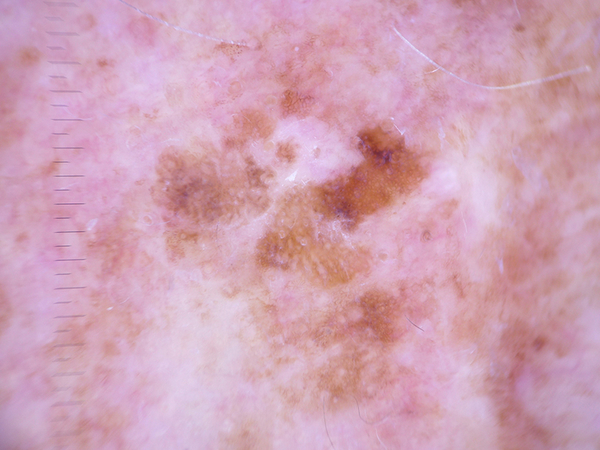

MULTIMODAL EFFICIENTNET-B0 PREDICTION
Age               : 50
Gender            : 0

Prediction
--------------------------------------------------
Diagnosis         : Benign
Binary Confidence : 76.40%
Lesion Type       : bkl
Lesion Confidence : 81.15%

Binary Probabilities
--------------------------------------------------
Benign    : 76.40%
Malignant : 23.60%

Lesion Probabilities
--------------------------------------------------
akiec     : 7.40%
bcc       : 1.83%
bkl       : 81.15%
df        : 0.22%
mel       : 4.05%
nv        : 5.16%
vasc      : 0.18%


In [21]:
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import transforms
from IPython.display import display

# ==============================
# IMAGE PATH
# ==============================

image_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027419.jpg"

# ==============================
# PATIENT INFORMATION
# ==============================

age = 50
gender = 0
# 0 = male
# 1 = female
# 2 = unknown

# ==============================
# LOAD IMAGE
# ==============================

image = Image.open(image_path).convert("RGB")

display(image)

# ==============================
# TRANSFORM
# ==============================

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0).to(device)

# ==============================
# METADATA
# ==============================

age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender],
    dtype=torch.long
).to(device)

# ==============================
# PREDICTION
# ==============================

model_mm.eval()

with torch.no_grad():

    lesion_output, binary_output = model_mm(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_probabilities = F.softmax(
        binary_output, dim=1
    )

    lesion_probabilities = F.softmax(
        lesion_output, dim=1
    )

    binary_prediction = torch.argmax(
        binary_probabilities, dim=1
    ).item()

    lesion_prediction = torch.argmax(
        lesion_probabilities, dim=1
    ).item()

# ==============================
# CLASS NAMES
# ==============================

binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

# ==============================
# CONFIDENCE
# ==============================

binary_confidence = (
    binary_probabilities[0][binary_prediction].item() * 100
)

lesion_confidence = (
    lesion_probabilities[0][lesion_prediction].item() * 100
)

# ==============================
# RESULTS
# ==============================

print("=" * 50)
print("MULTIMODAL EFFICIENTNET-B0 PREDICTION")
print("=" * 50)

print(f"Age               : {age}")
print(f"Gender            : {gender}")

print("\nPrediction")
print("-" * 50)

print(
    f"Diagnosis         : "
    f"{binary_names[binary_prediction]}"
)

print(
    f"Binary Confidence : "
    f"{binary_confidence:.2f}%"
)

print(
    f"Lesion Type       : "
    f"{lesion_names[lesion_prediction]}"
)

print(
    f"Lesion Confidence : "
    f"{lesion_confidence:.2f}%"
)

print("\nBinary Probabilities")
print("-" * 50)

for i, name in enumerate(binary_names):
    print(
        f"{name:10s}: "
        f"{binary_probabilities[0][i].item()*100:.2f}%"
    )

print("\nLesion Probabilities")
print("-" * 50)

for i, name in enumerate(lesion_names):
    print(
        f"{name:10s}: "
        f"{lesion_probabilities[0][i].item()*100:.2f}%"
    )

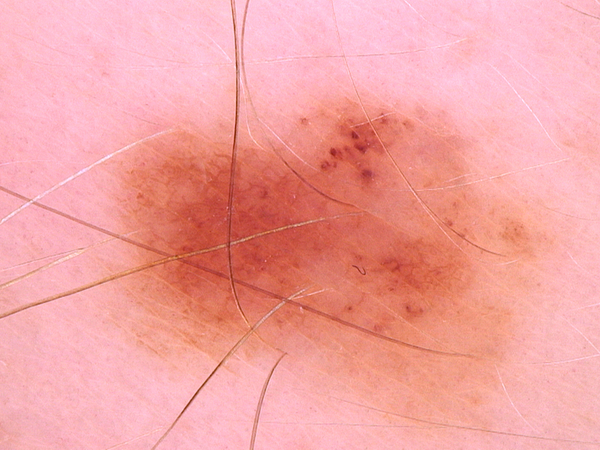

KNOWN HAM10000 IMAGE - MULTIMODAL PREDICTION
Image ID          : ISIC_0024872
Actual Diagnosis  : Benign
Actual Lesion     : nv
Age               : 50
Gender            : Male

MODEL PREDICTION
-------------------------------------------------------
Predicted Diagnosis : Benign
Binary Confidence   : 98.37%
Predicted Lesion    : nv
Lesion Confidence   : 98.73%

Binary Probabilities
-------------------------------------------------------
Benign    : 98.37%
Malignant : 1.63%

Lesion Probabilities
-------------------------------------------------------
akiec     : 0.01%
bcc       : 0.80%
bkl       : 0.11%
df        : 0.02%
mel       : 0.31%
nv        : 98.73%
vasc      : 0.01%


In [22]:
# ==========================================
# KNOWN HAM10000 BENIGN IMAGE PREDICTION
# MULTIMODAL EFFICIENTNET-B0
# ==========================================

from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from IPython.display import display

# Image
image_id = "ISIC_0024872"

image_path = image_path_map[image_id]

# Known metadata for demonstration
age = 50
gender = 0       # 0 = male

# Load image
image = Image.open(image_path).convert("RGB")

display(image)

# Transform
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0).to(device)

# Metadata
age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender],
    dtype=torch.long
).to(device)

# Prediction
model_mm.eval()

with torch.no_grad():

    lesion_output, binary_output = model_mm(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_prob = F.softmax(
        binary_output, dim=1
    )

    lesion_prob = F.softmax(
        lesion_output, dim=1
    )

    binary_pred = torch.argmax(
        binary_prob, dim=1
    ).item()

    lesion_pred = torch.argmax(
        lesion_prob, dim=1
    ).item()

# Class names
binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

# Results
binary_confidence = binary_prob[0][binary_pred].item() * 100
lesion_confidence = lesion_prob[0][lesion_pred].item() * 100

print("=" * 55)
print("KNOWN HAM10000 IMAGE - MULTIMODAL PREDICTION")
print("=" * 55)

print(f"Image ID          : {image_id}")
print(f"Actual Diagnosis  : Benign")
print(f"Actual Lesion     : nv")
print(f"Age               : {age}")
print(f"Gender            : Male")

print("\nMODEL PREDICTION")
print("-" * 55)

print(f"Predicted Diagnosis : {binary_names[binary_pred]}")
print(f"Binary Confidence   : {binary_confidence:.2f}%")
print(f"Predicted Lesion    : {lesion_names[lesion_pred]}")
print(f"Lesion Confidence   : {lesion_confidence:.2f}%")

print("\nBinary Probabilities")
print("-" * 55)

for i, name in enumerate(binary_names):
    print(
        f"{name:10s}: "
        f"{binary_prob[0][i].item() * 100:.2f}%"
    )

print("\nLesion Probabilities")
print("-" * 55)

for i, name in enumerate(lesion_names):
    print(
        f"{name:10s}: "
        f"{lesion_prob[0][i].item() * 100:.2f}%"
    )

Densenet121 multimodel

In [23]:
import torch
import torch.nn as nn
from torchvision import models

# ==========================================
# MULTIMODAL DENSENET121
# IMAGE + AGE + GENDER
# ==========================================

backbone_dense_mm = models.densenet121(weights="DEFAULT")


class MultiModalDenseNet(nn.Module):

    def __init__(self, backbone):

        super().__init__()

        # Image feature extractor
        self.features = backbone.features

        image_features = backbone.classifier.in_features

        # Age + Gender network
        self.metadata_net = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 32),
            nn.ReLU()
        )

        # Feature fusion
        self.fusion = nn.Sequential(
            nn.Linear(image_features + 32, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # 7-class lesion classification
        self.lesion_head = nn.Linear(256, 7)

        # Binary classification
        self.binary_head = nn.Linear(256, 2)


    def forward(self, image, age, gender):

        # --------------------------
        # Image features
        # --------------------------

        x = self.features(image)

        x = torch.relu(x)

        x = torch.nn.functional.adaptive_avg_pool2d(
            x, 1
        )

        x = torch.flatten(x, 1)

        # --------------------------
        # Metadata features
        # --------------------------

        metadata = torch.stack(
            [age, gender.float()],
            dim=1
        )

        metadata = self.metadata_net(metadata)

        # --------------------------
        # Feature fusion
        # --------------------------

        combined = torch.cat(
            [x, metadata],
            dim=1
        )

        combined = self.fusion(combined)

        # --------------------------
        # Outputs
        # --------------------------

        lesion_output = self.lesion_head(combined)

        binary_output = self.binary_head(combined)

        return lesion_output, binary_output


# Create model
model_mm_dense = MultiModalDenseNet(
    backbone_dense_mm
).to(device)

print(model_mm_dense)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 165MB/s] 


MultiModalDenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
   

In [24]:
# ==========================================
# LOSS FUNCTIONS
# ==========================================

lesion_weights_dense = torch.tensor(
    [4.2480, 2.8121, 1.3601, 13.3105, 1.2881, 0.2111, 11.7445],
    dtype=torch.float32
).to(device)

binary_weights_dense = torch.tensor(
    [0.6214, 2.5597],
    dtype=torch.float32
).to(device)


lesion_criterion_dense = nn.CrossEntropyLoss(
    weight=lesion_weights_dense
)

binary_criterion_dense = nn.CrossEntropyLoss(
    weight=binary_weights_dense
)


# ==========================================
# OPTIMIZER
# ==========================================

optimizer_mm_dense = torch.optim.Adam(
    model_mm_dense.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)


print("Multimodal DenseNet121 setup complete!")
print("Lesion loss  : Weighted CrossEntropyLoss")
print("Binary loss  : Weighted CrossEntropyLoss")
print("Optimizer    : Adam")
print("Learning rate: 0.0001")

Multimodal DenseNet121 setup complete!
Lesion loss  : Weighted CrossEntropyLoss
Binary loss  : Weighted CrossEntropyLoss
Optimizer    : Adam
Learning rate: 0.0001


Experimental Multimodal DenseNet121 — Alternative Split

In [25]:
# ==========================================
# TRAIN MULTIMODAL DENSENET121
# ==========================================

import os
import torch

checkpoint_dir = "/kaggle/working/multimodal_densenet_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_val_binary_acc = 0.0
best_epoch = 0

num_epochs = 10

for epoch in range(num_epochs):

    # ======================================
    # TRAINING
    # ======================================

    model_mm_dense.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, ages, genders, lesion_labels, binary_labels in train_loader:

        images = images.to(device, non_blocking=True)
        ages = ages.to(device, non_blocking=True)
        genders = genders.to(device, non_blocking=True)

        lesion_labels = lesion_labels.to(device, non_blocking=True)
        binary_labels = binary_labels.to(device, non_blocking=True)

        optimizer_mm_dense.zero_grad()

        lesion_output, binary_output = model_mm_dense(
            images,
            ages,
            genders
        )

        lesion_loss = lesion_criterion_dense(
            lesion_output,
            lesion_labels
        )

        binary_loss = binary_criterion_dense(
            binary_output,
            binary_labels
        )

        total_loss = lesion_loss + binary_loss

        total_loss.backward()

        optimizer_mm_dense.step()

        train_loss += total_loss.item()

        binary_predictions = torch.argmax(
            binary_output,
            dim=1
        )

        train_correct += (
            binary_predictions == binary_labels
        ).sum().item()

        train_total += binary_labels.size(0)

    train_loss /= len(train_loader)
    train_binary_acc = train_correct / train_total

    # ======================================
    # VALIDATION
    # ======================================

    model_mm_dense.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, ages, genders, lesion_labels, binary_labels in val_loader:

            images = images.to(device, non_blocking=True)
            ages = ages.to(device, non_blocking=True)
            genders = genders.to(device, non_blocking=True)

            lesion_labels = lesion_labels.to(device, non_blocking=True)
            binary_labels = binary_labels.to(device, non_blocking=True)

            lesion_output, binary_output = model_mm_dense(
                images,
                ages,
                genders
            )

            lesion_loss = lesion_criterion_dense(
                lesion_output,
                lesion_labels
            )

            binary_loss = binary_criterion_dense(
                binary_output,
                binary_labels
            )

            total_loss = lesion_loss + binary_loss

            val_loss += total_loss.item()

            binary_predictions = torch.argmax(
                binary_output,
                dim=1
            )

            val_correct += (
                binary_predictions == binary_labels
            ).sum().item()

            val_total += binary_labels.size(0)

    val_loss /= len(val_loader)
    val_binary_acc = val_correct / val_total

    # ======================================
    # PRINT RESULTS
    # ======================================

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Binary Acc: {train_binary_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Binary Acc: {val_binary_acc:.4f}"
    )

    # ======================================
    # SAVE BEST MODEL
    # ======================================

    if val_binary_acc > best_val_binary_acc:

        best_val_binary_acc = val_binary_acc
        best_epoch = epoch + 1

        best_path = os.path.join(
            checkpoint_dir,
            "best_multimodal_densenet.pth"
        )

        torch.save(
            model_mm_dense.state_dict(),
            best_path
        )

        print(
            f"  ✓ Best model saved "
            f"(Epoch {best_epoch})"
        )


print("\n" + "=" * 55)
print("TRAINING COMPLETE")
print("=" * 55)
print(f"Best Epoch              : {best_epoch}")
print(f"Best Validation Accuracy: {best_val_binary_acc:.4f}")
print(f"Model saved at          : {best_path}")

Epoch 1/10 | Train Loss: 1.7704 | Train Binary Acc: 0.7720 | Val Loss: 1.2172 | Val Binary Acc: 0.8386
  ✓ Best model saved (Epoch 1)
Epoch 2/10 | Train Loss: 1.1945 | Train Binary Acc: 0.8228 | Val Loss: 1.1315 | Val Binary Acc: 0.8280
Epoch 3/10 | Train Loss: 0.9928 | Train Binary Acc: 0.8436 | Val Loss: 0.9856 | Val Binary Acc: 0.8525
  ✓ Best model saved (Epoch 3)
Epoch 4/10 | Train Loss: 0.8343 | Train Binary Acc: 0.8648 | Val Loss: 1.0110 | Val Binary Acc: 0.8386
Epoch 5/10 | Train Loss: 0.7671 | Train Binary Acc: 0.8734 | Val Loss: 0.8921 | Val Binary Acc: 0.8439
Epoch 6/10 | Train Loss: 0.6688 | Train Binary Acc: 0.8912 | Val Loss: 0.9218 | Val Binary Acc: 0.8717
  ✓ Best model saved (Epoch 6)
Epoch 7/10 | Train Loss: 0.6082 | Train Binary Acc: 0.9010 | Val Loss: 1.0451 | Val Binary Acc: 0.8393
Epoch 8/10 | Train Loss: 0.5651 | Train Binary Acc: 0.9063 | Val Loss: 0.9177 | Val Binary Acc: 0.8525
Epoch 9/10 | Train Loss: 0.4741 | Train Binary Acc: 0.9233 | Val Loss: 0.9758 | Val

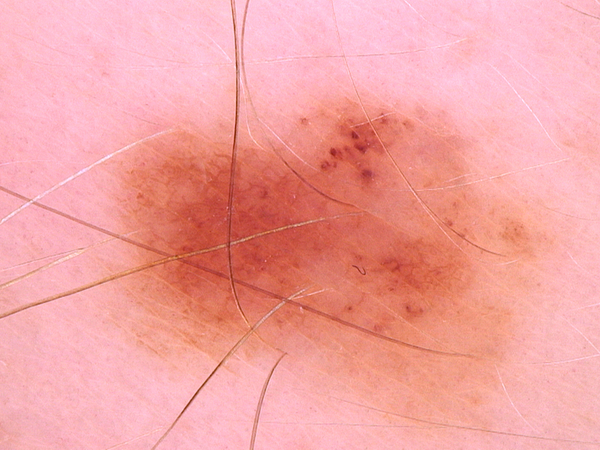

MULTIMODAL DENSENET121 PREDICTION
Image ID          : ISIC_0024872
Actual Diagnosis  : Benign
Actual Lesion     : nv
Age               : 50
Gender            : Male

MODEL PREDICTION
-------------------------------------------------------
Predicted Diagnosis : Benign
Binary Confidence   : 97.13%
Predicted Lesion    : nv
Lesion Confidence   : 97.87%

Binary Probabilities
-------------------------------------------------------
Benign    : 97.13%
Malignant : 2.87%

Lesion Probabilities
-------------------------------------------------------
akiec     : 0.04%
bcc       : 0.57%
bkl       : 0.13%
df        : 0.03%
mel       : 1.30%
nv        : 97.87%
vasc      : 0.05%


In [26]:
# ==========================================
# MULTIMODAL DENSENET121
# INDIVIDUAL PREDICTION
# ==========================================

from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from IPython.display import display

# ==========================================
# IMAGE
# ==========================================

image_id = "ISIC_0024872"
image_path = image_path_map[image_id]

image = Image.open(image_path).convert("RGB")

display(image)

# ==========================================
# PATIENT INFORMATION
# ==========================================

age = 50
gender = 0
# 0 = male
# 1 = female
# 2 = unknown

# ==========================================
# IMAGE TRANSFORM
# ==========================================

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0).to(device)

# ==========================================
# METADATA
# ==========================================

age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender],
    dtype=torch.long
).to(device)

# ==========================================
# LOAD BEST MODEL
# ==========================================

best_path = (
    "/kaggle/working/"
    "multimodal_densenet_checkpoints/"
    "best_multimodal_densenet.pth"
)

model_mm_dense.load_state_dict(
    torch.load(
        best_path,
        map_location=device,
        weights_only=True
    )
)

model_mm_dense = model_mm_dense.to(device)
model_mm_dense.eval()

# ==========================================
# PREDICTION
# ==========================================

with torch.no_grad():

    lesion_output, binary_output = model_mm_dense(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_prob = F.softmax(
        binary_output,
        dim=1
    )

    lesion_prob = F.softmax(
        lesion_output,
        dim=1
    )

    binary_pred = torch.argmax(
        binary_prob,
        dim=1
    ).item()

    lesion_pred = torch.argmax(
        lesion_prob,
        dim=1
    ).item()

# ==========================================
# CLASS NAMES
# ==========================================

binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

# ==========================================
# CONFIDENCE
# ==========================================

binary_confidence = (
    binary_prob[0][binary_pred].item() * 100
)

lesion_confidence = (
    lesion_prob[0][lesion_pred].item() * 100
)

# ==========================================
# DISPLAY RESULTS
# ==========================================

print("=" * 55)
print("MULTIMODAL DENSENET121 PREDICTION")
print("=" * 55)

print(f"Image ID          : {image_id}")
print("Actual Diagnosis  : Benign")
print("Actual Lesion     : nv")
print(f"Age               : {age}")
print("Gender            : Male")

print("\nMODEL PREDICTION")
print("-" * 55)

print(
    f"Predicted Diagnosis : "
    f"{binary_names[binary_pred]}"
)

print(
    f"Binary Confidence   : "
    f"{binary_confidence:.2f}%"
)

print(
    f"Predicted Lesion    : "
    f"{lesion_names[lesion_pred]}"
)

print(
    f"Lesion Confidence   : "
    f"{lesion_confidence:.2f}%"
)

print("\nBinary Probabilities")
print("-" * 55)

for i, name in enumerate(binary_names):

    print(
        f"{name:10s}: "
        f"{binary_prob[0][i].item() * 100:.2f}%"
    )

print("\nLesion Probabilities")
print("-" * 55)

for i, name in enumerate(lesion_names):

    print(
        f"{name:10s}: "
        f"{lesion_prob[0][i].item() * 100:.2f}%"
    )

In [27]:
# ==========================================
# EXACT ORIGINAL COLAB SPLIT
# Multilabel Stratified + Lesion Level
# ==========================================

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# ------------------------------------------
# Create lesion-level dataframe
# ------------------------------------------

lesion_df = (
    df.groupby("lesion_id")
      .agg({
          "dx": "first"
      })
      .reset_index()
)

print("Lesion-level records:", len(lesion_df))

# ------------------------------------------
# One-hot encode diagnosis
# ------------------------------------------

lesion_labels = pd.get_dummies(
    lesion_df["dx"]
)

# ------------------------------------------
# FIRST SPLIT
# 70% Train / 30% Temporary
# ------------------------------------------

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    msss.split(
        lesion_df,
        lesion_labels
    )
)

train_lesion_ids = set(
    lesion_df.iloc[train_idx]["lesion_id"]
)

temp_lesion_ids = set(
    lesion_df.iloc[temp_idx]["lesion_id"]
)

print("\nAfter first split:")
print("Train lesions     :", len(train_lesion_ids))
print("Temporary lesions :", len(temp_lesion_ids))

# ------------------------------------------
# SECOND SPLIT
# 50% Validation / 50% Test
# ------------------------------------------

temp_df = lesion_df[
    lesion_df["lesion_id"].isin(
        temp_lesion_ids
    )
].reset_index(drop=True)

temp_labels = pd.get_dummies(
    temp_df["dx"]
)

msss2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    msss2.split(
        temp_df,
        temp_labels
    )
)

val_lesion_ids = set(
    temp_df.iloc[val_idx]["lesion_id"]
)

test_lesion_ids = set(
    temp_df.iloc[test_idx]["lesion_id"]
)

print("\nAfter second split:")
print("Validation lesions :", len(val_lesion_ids))
print("Test lesions       :", len(test_lesion_ids))

# ------------------------------------------
# CREATE FINAL DATAFRAMES
# ------------------------------------------

train_df = df[
    df["lesion_id"].isin(
        train_lesion_ids
    )
].copy()

val_df = df[
    df["lesion_id"].isin(
        val_lesion_ids
    )
].copy()

test_df = df[
    df["lesion_id"].isin(
        test_lesion_ids
    )
].copy()

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------
# CHECK SIZES
# ------------------------------------------

print("\n" + "=" * 55)
print("EXACT ORIGINAL SPLIT")
print("=" * 55)

print("Train images      :", len(train_df))
print("Validation images :", len(val_df))
print("Test images       :", len(test_df))
print("Total             :", len(train_df) + len(val_df) + len(test_df))

print("\nUnique lesions:")
print("Train      :", train_df["lesion_id"].nunique())
print("Validation :", val_df["lesion_id"].nunique())
print("Test       :", test_df["lesion_id"].nunique())

# ------------------------------------------
# OVERLAP CHECK
# ------------------------------------------

train_set = set(train_df["lesion_id"])
val_set = set(val_df["lesion_id"])
test_set = set(test_df["lesion_id"])

print("\nLesion overlap:")
print(
    "Train ∩ Validation :",
    len(train_set & val_set)
)

print(
    "Train ∩ Test       :",
    len(train_set & test_set)
)

print(
    "Validation ∩ Test  :",
    len(val_set & test_set)
)

# ------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------

if (
    len(train_df) == 6990
    and len(val_df) == 1533
    and len(test_df) == 1492
    and len(train_set & val_set) == 0
    and len(train_set & test_set) == 0
    and len(val_set & test_set) == 0
):

    print("\n" + "=" * 55)
    print("✅ EXACT COLAB SPLIT RECREATED!")
    print("=" * 55)

else:

    print("\n" + "=" * 55)
    print("❌ SPLIT DOES NOT MATCH")
    print("=" * 55)

Lesion-level records: 7470

After first split:
Train lesions     : 5230
Temporary lesions : 2240

After second split:
Validation lesions : 1120
Test lesions       : 1120

EXACT ORIGINAL SPLIT
Train images      : 6990
Validation images : 1533
Test images       : 1492
Total             : 10015

Unique lesions:
Train      : 5230
Validation : 1120
Test       : 1120

Lesion overlap:
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ EXACT COLAB SPLIT RECREATED!


In [28]:
# ============================================================
# MULTIMODAL DATASET + DATALOADERS
# EXACT COLAB SPLIT
# Image + Age + Gender
# ============================================================

from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch
import glob
import os

# ------------------------------------------------------------
# Metadata / label preparation
# ------------------------------------------------------------

gender_mapping = {
    "male": 0,
    "female": 1,
    "unknown": 2
}

lesion_mapping = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

# Make sure there are no missing ages
median_age = train_df["age"].median()

train_df["age"] = train_df["age"].fillna(median_age)
val_df["age"] = val_df["age"].fillna(median_age)
test_df["age"] = test_df["age"].fillna(median_age)

# Encode gender
for data in [train_df, val_df, test_df]:

    data["sex_encoded"] = (
        data["sex"]
        .str.lower()
        .map(gender_mapping)
        .fillna(2)
        .astype(int)
    )

    data["lesion_label"] = (
        data["dx"]
        .map(lesion_mapping)
        .astype(int)
    )

print("Missing ages:")
print("Train:", train_df["age"].isna().sum())
print("Val  :", val_df["age"].isna().sum())
print("Test :", test_df["age"].isna().sum())

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class MultiModalSkinDataset(Dataset):

    def __init__(self, df, image_path_map, transform=None):

        self.df = df.reset_index(drop=True)
        self.image_path_map = image_path_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_id = row["image_id"]

        image_path = self.image_path_map[image_id]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # Normalize age to 0-1
        age = torch.tensor(
            row["age"] / 100.0,
            dtype=torch.float32
        )

        gender = torch.tensor(
            row["sex_encoded"],
            dtype=torch.long
        )

        lesion_label = torch.tensor(
            row["lesion_label"],
            dtype=torch.long
        )

        binary_label = torch.tensor(
            row["binary_label"],
            dtype=torch.long
        )

        return (
            image,
            age,
            gender,
            lesion_label,
            binary_label
        )

# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_multi_dataset = MultiModalSkinDataset(
    train_df,
    image_path_map,
    transform=train_transform
)

val_multi_dataset = MultiModalSkinDataset(
    val_df,
    image_path_map,
    transform=val_test_transform
)

test_multi_dataset = MultiModalSkinDataset(
    test_df,
    image_path_map,
    transform=val_test_transform
)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_multi_loader = DataLoader(
    train_multi_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_multi_loader = DataLoader(
    val_multi_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_multi_loader = DataLoader(
    test_multi_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------------------
# Check one batch
# ------------------------------------------------------------

images, ages, genders, lesion_labels, binary_labels = next(
    iter(train_multi_loader)
)

print("\n" + "=" * 60)
print("MULTIMODAL DATALOADER CHECK")
print("=" * 60)

print("Images shape        :", images.shape)
print("Ages shape          :", ages.shape)
print("Genders shape       :", genders.shape)
print("Lesion labels shape :", lesion_labels.shape)
print("Binary labels shape :", binary_labels.shape)

print("\nAge NaN :", torch.isnan(ages).any().item())
print("Age Inf :", torch.isinf(ages).any().item())

print("\nTrain samples      :", len(train_multi_dataset))
print("Validation samples :", len(val_multi_dataset))
print("Test samples       :", len(test_multi_dataset))

print("\n✅ Exact Colab multimodal split is ready!")

Missing ages:
Train: 0
Val  : 0
Test : 0

MULTIMODAL DATALOADER CHECK
Images shape        : torch.Size([32, 3, 224, 224])
Ages shape          : torch.Size([32])
Genders shape       : torch.Size([32])
Lesion labels shape : torch.Size([32])
Binary labels shape : torch.Size([32])

Age NaN : False
Age Inf : False

Train samples      : 6990
Validation samples : 1533
Test samples       : 1492

✅ Exact Colab multimodal split is ready!


In [29]:
# ============================================================
# MULTIMODAL EFFICIENTNET-B0
# Image + Age + Gender
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MultiModalEfficientNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Pretrained EfficientNet-B0
        backbone = models.efficientnet_b0(weights="DEFAULT")

        # Image feature extractor
        self.features = backbone.features

        # EfficientNet-B0 output = 1280 features
        self.image_feature_size = backbone.classifier[1].in_features

        # Metadata network
        # Input: Age + Gender
        self.metadata_network = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 32),
            nn.ReLU()
        )

        # Fusion layer
        # 1280 image features + 32 metadata features
        self.fusion = nn.Sequential(
            nn.Linear(self.image_feature_size + 32, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # 7-class lesion classification
        self.lesion_head = nn.Linear(256, 7)

        # Binary classification
        # 0 = Benign
        # 1 = Malignant
        self.binary_head = nn.Linear(256, 2)

    def forward(self, image, age, gender):

        # -------------------------
        # Image features
        # -------------------------
        x = self.features(image)

        x = torch.nn.functional.adaptive_avg_pool2d(x, 1)

        x = torch.flatten(x, 1)

        # -------------------------
        # Metadata features
        # -------------------------
        metadata = torch.stack(
            [age, gender.float()],
            dim=1
        )

        metadata_features = self.metadata_network(metadata)

        # -------------------------
        # Feature fusion
        # -------------------------
        combined = torch.cat(
            [x, metadata_features],
            dim=1
        )

        fused = self.fusion(combined)

        # -------------------------
        # Outputs
        # -------------------------
        lesion_output = self.lesion_head(fused)

        binary_output = self.binary_head(fused)

        return lesion_output, binary_output


# Create model
model_mm = MultiModalEfficientNet().to(device)

print("=" * 60)
print("MULTIMODAL EFFICIENTNET-B0")
print("=" * 60)

print("Device:", device)
print("Image features:", model_mm.image_feature_size)
print("Metadata features:", 32)
print("Fusion input:", model_mm.image_feature_size + 32)
print("Fusion output:", 256)

print("\n✅ Multimodal model created successfully!")

MULTIMODAL EFFICIENTNET-B0
Device: cuda
Image features: 1280
Metadata features: 32
Fusion input: 1312
Fusion output: 256

✅ Multimodal model created successfully!


In [30]:
# ============================================================
# CLASS WEIGHTS + LOSS + OPTIMIZER
# EXACT COLAB SPLIT
# ============================================================

import torch
import torch.nn as nn
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# 1. Lesion class weights (7 classes)
# ------------------------------------------------------------

lesion_classes = np.arange(7)

lesion_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=lesion_classes,
    y=train_df["lesion_label"].values
)

lesion_weights = torch.tensor(
    lesion_weights_np,
    dtype=torch.float32
).to(device)


# ------------------------------------------------------------
# 2. Binary class weights
# 0 = Benign
# 1 = Malignant
# ------------------------------------------------------------

binary_classes = np.arange(2)

binary_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=binary_classes,
    y=train_df["binary_label"].values
)

binary_weights = torch.tensor(
    binary_weights_np,
    dtype=torch.float32
).to(device)


# ------------------------------------------------------------
# 3. Loss functions
# ------------------------------------------------------------

lesion_criterion = nn.CrossEntropyLoss(
    weight=lesion_weights
)

binary_criterion = nn.CrossEntropyLoss(
    weight=binary_weights
)


# ------------------------------------------------------------
# 4. Optimizer
# ------------------------------------------------------------

optimizer_mm = torch.optim.Adam(
    model_mm.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

print("\nLesion weights:")
for i, weight in enumerate(lesion_weights):
    print(f"{i}: {weight.item():.4f}")

print("\nBinary weights:")
for i, weight in enumerate(binary_weights):
    print(f"{i}: {weight.item():.4f}")

print("\nLearning rate : 0.0001")
print("Weight decay  : 1e-4")

print("\n✅ Loss functions and optimizer are ready!")

CLASS WEIGHTS

Lesion weights:
0: 4.4779
1: 2.8449
2: 1.3122
3: 12.4821
4: 1.2529
5: 0.2135
6: 9.8868

Binary weights:
0: 0.6220
1: 2.5492

Learning rate : 0.0001
Weight decay  : 1e-4

✅ Loss functions and optimizer are ready!


In [31]:
# ============================================================
# TRAIN MULTIMODAL EFFICIENTNET-B0
# EXACT COLAB SPLIT
# Image + Age + Gender
# ============================================================

import os
import torch

# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

checkpoint_dir = "/kaggle/working/multimodal_exact_split_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_model_path = os.path.join(
    checkpoint_dir,
    "best_multimodal_efficientnet_exact_split.pth"
)

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

num_epochs = 10
best_val_binary_acc = 0.0
best_epoch = 0

print("=" * 60)
print("MULTIMODAL TRAINING")
print("=" * 60)
print("Epochs:", num_epochs)
print("Device:", device)
print("Checkpoint:", best_model_path)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

for epoch in range(num_epochs):

    # ========================================================
    # TRAIN
    # ========================================================

    model_mm.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, ages, genders, lesion_labels, binary_labels in train_multi_loader:

        images = images.to(device, non_blocking=True)
        ages = ages.to(device, non_blocking=True)
        genders = genders.to(device, non_blocking=True)
        lesion_labels = lesion_labels.to(device, non_blocking=True)
        binary_labels = binary_labels.to(device, non_blocking=True)

        optimizer_mm.zero_grad()

        # Forward pass
        lesion_output, binary_output = model_mm(
            images,
            ages,
            genders
        )

        # Losses
        lesion_loss = lesion_criterion(
            lesion_output,
            lesion_labels
        )

        binary_loss = binary_criterion(
            binary_output,
            binary_labels
        )

        # Total loss
        total_loss = lesion_loss + binary_loss

        # Backpropagation
        total_loss.backward()

        optimizer_mm.step()

        # Statistics
        train_loss += total_loss.item() * images.size(0)

        binary_predictions = torch.argmax(
            binary_output,
            dim=1
        )

        train_correct += (
            binary_predictions == binary_labels
        ).sum().item()

        train_total += images.size(0)

    train_loss /= train_total
    train_binary_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    model_mm.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, ages, genders, lesion_labels, binary_labels in val_multi_loader:

            images = images.to(device, non_blocking=True)
            ages = ages.to(device, non_blocking=True)
            genders = genders.to(device, non_blocking=True)
            lesion_labels = lesion_labels.to(device, non_blocking=True)
            binary_labels = binary_labels.to(device, non_blocking=True)

            # Forward pass
            lesion_output, binary_output = model_mm(
                images,
                ages,
                genders
            )

            # Losses
            lesion_loss = lesion_criterion(
                lesion_output,
                lesion_labels
            )

            binary_loss = binary_criterion(
                binary_output,
                binary_labels
            )

            total_loss = lesion_loss + binary_loss

            # Statistics
            val_loss += total_loss.item() * images.size(0)

            binary_predictions = torch.argmax(
                binary_output,
                dim=1
            )

            val_correct += (
                binary_predictions == binary_labels
            ).sum().item()

            val_total += images.size(0)

    val_loss /= val_total
    val_binary_acc = val_correct / val_total


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Binary Acc: {train_binary_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Binary Acc: {val_binary_acc:.4f}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_binary_acc > best_val_binary_acc:

        best_val_binary_acc = val_binary_acc
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_mm.state_dict(),
                "val_binary_acc": val_binary_acc
            },
            best_model_path
        )

        print(
            f"   ✅ New best model saved "
            f"(Epoch {best_epoch}, "
            f"Val Binary Acc: {best_val_binary_acc:.4f})"
        )


print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best Epoch: {best_epoch}"
)

print(
    f"Best Validation Binary Accuracy: "
    f"{best_val_binary_acc:.4f}"
)

print(
    f"Best model saved at:\n{best_model_path}"
)

print("\n✅ Multimodal training finished!")

MULTIMODAL TRAINING
Epochs: 10
Device: cuda
Checkpoint: /kaggle/working/multimodal_exact_split_checkpoints/best_multimodal_efficientnet_exact_split.pth
Epoch [1/10] Train Loss: 1.9077 Train Binary Acc: 0.7481 Val Loss: 1.4461 Val Binary Acc: 0.7645
   ✅ New best model saved (Epoch 1, Val Binary Acc: 0.7645)
Epoch [2/10] Train Loss: 1.1564 Train Binary Acc: 0.8252 Val Loss: 1.1445 Val Binary Acc: 0.8278
   ✅ New best model saved (Epoch 2, Val Binary Acc: 0.8278)
Epoch [3/10] Train Loss: 0.8945 Train Binary Acc: 0.8551 Val Loss: 1.0258 Val Binary Acc: 0.8408
   ✅ New best model saved (Epoch 3, Val Binary Acc: 0.8408)
Epoch [4/10] Train Loss: 0.7798 Train Binary Acc: 0.8741 Val Loss: 0.9189 Val Binary Acc: 0.8800
   ✅ New best model saved (Epoch 4, Val Binary Acc: 0.8800)
Epoch [5/10] Train Loss: 0.6558 Train Binary Acc: 0.8884 Val Loss: 0.9921 Val Binary Acc: 0.8598
Epoch [6/10] Train Loss: 0.5717 Train Binary Acc: 0.9023 Val Loss: 0.9639 Val Binary Acc: 0.8513
Epoch [7/10] Train Loss: 0

In [32]:
# ============================================================
# FINAL TEST EVALUATION
# MULTIMODAL EFFICIENTNET-B0
# Image + Age + Gender
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Load best model
# ------------------------------------------------------------

checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model_mm.load_state_dict(
    checkpoint["model_state_dict"]
)

model_mm.to(device)
model_mm.eval()

print("=" * 60)
print("LOADED BEST MULTIMODAL MODEL")
print("=" * 60)
print("Best Epoch:", checkpoint["epoch"])
print(
    "Best Validation Binary Accuracy:",
    f"{checkpoint['val_binary_acc']:.4f}"
)

# ------------------------------------------------------------
# Store predictions
# ------------------------------------------------------------

all_binary_true = []
all_binary_pred = []

all_lesion_true = []
all_lesion_pred = []

# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

with torch.no_grad():

    for images, ages, genders, lesion_labels, binary_labels in test_multi_loader:

        images = images.to(device, non_blocking=True)
        ages = ages.to(device, non_blocking=True)
        genders = genders.to(device, non_blocking=True)

        lesion_labels = lesion_labels.to(device)
        binary_labels = binary_labels.to(device)

        # Forward pass
        lesion_output, binary_output = model_mm(
            images,
            ages,
            genders
        )

        # Predictions
        lesion_predictions = torch.argmax(
            lesion_output,
            dim=1
        )

        binary_predictions = torch.argmax(
            binary_output,
            dim=1
        )

        # Store
        all_binary_true.extend(
            binary_labels.cpu().numpy()
        )

        all_binary_pred.extend(
            binary_predictions.cpu().numpy()
        )

        all_lesion_true.extend(
            lesion_labels.cpu().numpy()
        )

        all_lesion_pred.extend(
            lesion_predictions.cpu().numpy()
        )


# ============================================================
# BINARY RESULTS
# ============================================================

binary_accuracy = accuracy_score(
    all_binary_true,
    all_binary_pred
)

binary_precision = precision_score(
    all_binary_true,
    all_binary_pred,
    average="weighted",
    zero_division=0
)

binary_recall = recall_score(
    all_binary_true,
    all_binary_pred,
    average="weighted",
    zero_division=0
)

binary_f1 = f1_score(
    all_binary_true,
    all_binary_pred,
    average="weighted",
    zero_division=0
)

binary_cm = confusion_matrix(
    all_binary_true,
    all_binary_pred
)


print("\n" + "=" * 60)
print("BINARY CLASSIFICATION")
print("=" * 60)

print(f"Accuracy  : {binary_accuracy:.4f}")
print(f"Precision : {binary_precision:.4f}")
print(f"Recall    : {binary_recall:.4f}")
print(f"F1 Score  : {binary_f1:.4f}")

print("\nConfusion Matrix:")
print(binary_cm)

print("\nClassification Report:")
print(
    classification_report(
        all_binary_true,
        all_binary_pred,
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)


# ============================================================
# 7-CLASS LESION RESULTS
# ============================================================

lesion_accuracy = accuracy_score(
    all_lesion_true,
    all_lesion_pred
)

lesion_precision = precision_score(
    all_lesion_true,
    all_lesion_pred,
    average="weighted",
    zero_division=0
)

lesion_recall = recall_score(
    all_lesion_true,
    all_lesion_pred,
    average="weighted",
    zero_division=0
)

lesion_f1 = f1_score(
    all_lesion_true,
    all_lesion_pred,
    average="weighted",
    zero_division=0
)

lesion_cm = confusion_matrix(
    all_lesion_true,
    all_lesion_pred
)


lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]


print("\n" + "=" * 60)
print("7-CLASS LESION CLASSIFICATION")
print("=" * 60)

print(f"Accuracy  : {lesion_accuracy:.4f}")
print(f"Precision : {lesion_precision:.4f}")
print(f"Recall    : {lesion_recall:.4f}")
print(f"F1 Score  : {lesion_f1:.4f}")

print("\nConfusion Matrix:")
print(lesion_cm)

print("\nClassification Report:")
print(
    classification_report(
        all_lesion_true,
        all_lesion_pred,
        target_names=lesion_names,
        zero_division=0
    )
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL MULTIMODAL RESULTS")
print("=" * 60)

print(f"Binary Accuracy : {binary_accuracy * 100:.2f}%")
print(f"Binary F1       : {binary_f1 * 100:.2f}%")

print(f"Lesion Accuracy : {lesion_accuracy * 100:.2f}%")
print(f"Lesion F1       : {lesion_f1 * 100:.2f}%")

print("\n✅ Final multimodal test evaluation complete!")

LOADED BEST MULTIMODAL MODEL
Best Epoch: 4
Best Validation Binary Accuracy: 0.8800

BINARY CLASSIFICATION
Accuracy  : 0.8881
Precision : 0.8922
Recall    : 0.8881
F1 Score  : 0.8898

Confusion Matrix:
[[1109   96]
 [  71  216]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.94      0.92      0.93      1205
   Malignant       0.69      0.75      0.72       287

    accuracy                           0.89      1492
   macro avg       0.82      0.84      0.83      1492
weighted avg       0.89      0.89      0.89      1492


7-CLASS LESION CLASSIFICATION
Accuracy  : 0.8177
Precision : 0.8298
Recall    : 0.8177
F1 Score  : 0.8212

Confusion Matrix:
[[ 35   3   6  10   1   0   0]
 [  3  72   4   1   0   0   1]
 [  8   8 105   5  16  19   1]
 [  1   2   0  14   1   2   0]
 [  7   9  22   1  78  34   0]
 [  1  19  40   3  39 897   4]
 [  0   1   0   0   0   0  19]]

Classification Report:
              precision    recall  f1-score   support

Densenet121 again

In [33]:
# ============================================================
# MULTIMODAL DENSENET121
# Image + Age + Gender
# EXACT COLAB SPLIT
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MultiModalDenseNet(nn.Module):

    def __init__(self):
        super().__init__()

        # ----------------------------------------------------
        # Pretrained DenseNet121
        # ----------------------------------------------------

        backbone = models.densenet121(weights="DEFAULT")

        # Image feature extractor
        self.features = backbone.features

        # DenseNet121 output feature size
        self.image_feature_size = backbone.classifier.in_features


        # ----------------------------------------------------
        # Metadata Network
        # Input:
        #   Age
        #   Gender
        # ----------------------------------------------------

        self.metadata_network = nn.Sequential(

            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 32),
            nn.ReLU()
        )


        # ----------------------------------------------------
        # Feature Fusion
        # DenseNet features + metadata features
        # ----------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                self.image_feature_size + 32,
                256
            ),

            nn.ReLU(),
            nn.Dropout(0.3)
        )


        # ----------------------------------------------------
        # Output Heads
        # ----------------------------------------------------

        # 7 lesion classes
        self.lesion_head = nn.Linear(256, 7)

        # 2 binary classes
        # 0 = Benign
        # 1 = Malignant
        self.binary_head = nn.Linear(256, 2)


    def forward(self, image, age, gender):

        # ----------------------------------------------------
        # Image features
        # ----------------------------------------------------

        x = self.features(image)

        x = torch.relu(x)

        x = torch.nn.functional.adaptive_avg_pool2d(
            x, 1
        )

        x = torch.flatten(x, 1)


        # ----------------------------------------------------
        # Metadata features
        # ----------------------------------------------------

        metadata = torch.stack(
            [age, gender.float()],
            dim=1
        )

        metadata_features = self.metadata_network(
            metadata
        )


        # ----------------------------------------------------
        # Feature Fusion
        # ----------------------------------------------------

        combined = torch.cat(
            [x, metadata_features],
            dim=1
        )

        fused = self.fusion(combined)


        # ----------------------------------------------------
        # Predictions
        # ----------------------------------------------------

        lesion_output = self.lesion_head(fused)

        binary_output = self.binary_head(fused)

        return lesion_output, binary_output


# ============================================================
# Create model
# ============================================================

model_mm_dense = MultiModalDenseNet().to(device)


print("=" * 60)
print("MULTIMODAL DENSENET121")
print("=" * 60)

print("Device:", device)
print(
    "Image features:",
    model_mm_dense.image_feature_size
)
print("Metadata features:", 32)
print(
    "Fusion input:",
    model_mm_dense.image_feature_size + 32
)
print("Fusion output:", 256)

print("\n✅ Multimodal DenseNet121 created successfully!")

MULTIMODAL DENSENET121
Device: cuda
Image features: 1024
Metadata features: 32
Fusion input: 1056
Fusion output: 256

✅ Multimodal DenseNet121 created successfully!


In [34]:
# ============================================================
# MULTIMODAL DENSENET121
# CLASS WEIGHTS + LOSS + OPTIMIZER
# EXACT COLAB SPLIT
# ============================================================

import torch
import torch.nn as nn
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# 1. Lesion class weights
# ------------------------------------------------------------

lesion_classes = np.arange(7)

lesion_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=lesion_classes,
    y=train_df["lesion_label"].values
)

lesion_weights_dense = torch.tensor(
    lesion_weights_np,
    dtype=torch.float32
).to(device)


# ------------------------------------------------------------
# 2. Binary class weights
# ------------------------------------------------------------

binary_classes = np.arange(2)

binary_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=binary_classes,
    y=train_df["binary_label"].values
)

binary_weights_dense = torch.tensor(
    binary_weights_np,
    dtype=torch.float32
).to(device)


# ------------------------------------------------------------
# 3. Loss functions
# ------------------------------------------------------------

lesion_criterion_dense = nn.CrossEntropyLoss(
    weight=lesion_weights_dense
)

binary_criterion_dense = nn.CrossEntropyLoss(
    weight=binary_weights_dense
)


# ------------------------------------------------------------
# 4. Optimizer
# ------------------------------------------------------------

optimizer_mm_dense = torch.optim.Adam(
    model_mm_dense.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 60)
print("MULTIMODAL DENSENET121 - CLASS WEIGHTS")
print("=" * 60)

print("\nLesion weights:")

for i, weight in enumerate(lesion_weights_dense):
    print(f"{i}: {weight.item():.4f}")


print("\nBinary weights:")

for i, weight in enumerate(binary_weights_dense):
    print(f"{i}: {weight.item():.4f}")


print("\nLearning rate : 0.0001")
print("Weight decay  : 1e-4")

print("\n✅ Loss functions and optimizer are ready!")

MULTIMODAL DENSENET121 - CLASS WEIGHTS

Lesion weights:
0: 4.4779
1: 2.8449
2: 1.3122
3: 12.4821
4: 1.2529
5: 0.2135
6: 9.8868

Binary weights:
0: 0.6220
1: 2.5492

Learning rate : 0.0001
Weight decay  : 1e-4

✅ Loss functions and optimizer are ready!


In [35]:
# ============================================================
# TRAIN MULTIMODAL DENSENET121
# Image + Age + Gender
# EXACT COLAB SPLIT
# ============================================================

import os
import torch

# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

checkpoint_dir_dense = (
    "/kaggle/working/"
    "multimodal_densenet_exact_split_checkpoints"
)

os.makedirs(checkpoint_dir_dense, exist_ok=True)

best_model_path_dense = os.path.join(
    checkpoint_dir_dense,
    "best_multimodal_densenet_exact_split.pth"
)


# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

num_epochs = 10
best_val_binary_acc_dense = 0.0
best_epoch_dense = 0

print("=" * 60)
print("MULTIMODAL DENSENET121 TRAINING")
print("=" * 60)

print("Epochs:", num_epochs)
print("Device:", device)

print(
    "Checkpoint:",
    best_model_path_dense
)


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(num_epochs):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model_mm_dense.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for (
        images,
        ages,
        genders,
        lesion_labels,
        binary_labels
    ) in train_multi_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        ages = ages.to(
            device,
            non_blocking=True
        )

        genders = genders.to(
            device,
            non_blocking=True
        )

        lesion_labels = lesion_labels.to(device)

        binary_labels = binary_labels.to(device)


        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        optimizer_mm_dense.zero_grad()


        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        lesion_output, binary_output = model_mm_dense(
            images,
            ages,
            genders
        )


        # ----------------------------------------------------
        # Calculate losses
        # ----------------------------------------------------

        lesion_loss = lesion_criterion_dense(
            lesion_output,
            lesion_labels
        )

        binary_loss = binary_criterion_dense(
            binary_output,
            binary_labels
        )


        # Total loss
        total_loss = (
            lesion_loss +
            binary_loss
        )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        total_loss.backward()

        optimizer_mm_dense.step()


        # ----------------------------------------------------
        # Training statistics
        # ----------------------------------------------------

        train_loss += (
            total_loss.item() *
            images.size(0)
        )

        binary_predictions = torch.argmax(
            binary_output,
            dim=1
        )

        train_correct += (
            binary_predictions ==
            binary_labels
        ).sum().item()

        train_total += images.size(0)


    train_loss /= train_total

    train_binary_acc = (
        train_correct /
        train_total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model_mm_dense.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0


    with torch.no_grad():

        for (
            images,
            ages,
            genders,
            lesion_labels,
            binary_labels
        ) in val_multi_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            ages = ages.to(
                device,
                non_blocking=True
            )

            genders = genders.to(
                device,
                non_blocking=True
            )

            lesion_labels = lesion_labels.to(device)

            binary_labels = binary_labels.to(device)


            # Forward pass
            lesion_output, binary_output = model_mm_dense(
                images,
                ages,
                genders
            )


            # Losses
            lesion_loss = lesion_criterion_dense(
                lesion_output,
                lesion_labels
            )

            binary_loss = binary_criterion_dense(
                binary_output,
                binary_labels
            )

            total_loss = (
                lesion_loss +
                binary_loss
            )


            # Validation statistics
            val_loss += (
                total_loss.item() *
                images.size(0)
            )

            binary_predictions = torch.argmax(
                binary_output,
                dim=1
            )

            val_correct += (
                binary_predictions ==
                binary_labels
            ).sum().item()

            val_total += images.size(0)


    val_loss /= val_total

    val_binary_acc = (
        val_correct /
        val_total
    )


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Binary Acc: {train_binary_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Binary Acc: {val_binary_acc:.4f}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_binary_acc > best_val_binary_acc_dense:

        best_val_binary_acc_dense = val_binary_acc

        best_epoch_dense = epoch + 1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict":
                    model_mm_dense.state_dict(),
                "val_binary_acc":
                    val_binary_acc
            },
            best_model_path_dense
        )

        print(
            f"   ✅ New best model saved "
            f"(Epoch {best_epoch_dense}, "
            f"Val Binary Acc: "
            f"{best_val_binary_acc_dense:.4f})"
        )


# ============================================================
# TRAINING COMPLETE
# ============================================================

print("\n" + "=" * 60)
print("MULTIMODAL DENSENET121 TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best Epoch: {best_epoch_dense}"
)

print(
    f"Best Validation Binary Accuracy: "
    f"{best_val_binary_acc_dense:.4f}"
)

print(
    f"Best model saved at:\n"
    f"{best_model_path_dense}"
)

print("\n✅ Training finished successfully!")

MULTIMODAL DENSENET121 TRAINING
Epochs: 10
Device: cuda
Checkpoint: /kaggle/working/multimodal_densenet_exact_split_checkpoints/best_multimodal_densenet_exact_split.pth
Epoch [1/10] Train Loss: 1.7031 Train Binary Acc: 0.7735 Val Loss: 1.3451 Val Binary Acc: 0.8200
   ✅ New best model saved (Epoch 1, Val Binary Acc: 0.8200)
Epoch [2/10] Train Loss: 1.1880 Train Binary Acc: 0.8169 Val Loss: 1.2894 Val Binary Acc: 0.8121
Epoch [3/10] Train Loss: 0.9910 Train Binary Acc: 0.8474 Val Loss: 1.0612 Val Binary Acc: 0.8382
   ✅ New best model saved (Epoch 3, Val Binary Acc: 0.8382)
Epoch [4/10] Train Loss: 0.8793 Train Binary Acc: 0.8602 Val Loss: 1.1582 Val Binary Acc: 0.8252
Epoch [5/10] Train Loss: 0.7476 Train Binary Acc: 0.8781 Val Loss: 1.0509 Val Binary Acc: 0.8506
   ✅ New best model saved (Epoch 5, Val Binary Acc: 0.8506)
Epoch [6/10] Train Loss: 0.6955 Train Binary Acc: 0.8838 Val Loss: 1.0165 Val Binary Acc: 0.8545
   ✅ New best model saved (Epoch 6, Val Binary Acc: 0.8545)
Epoch [7/

In [36]:
# ============================================================
# FINAL TEST EVALUATION
# MULTIMODAL DENSENET121
# Image + Age + Gender
# ============================================================

import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Load best model
# ------------------------------------------------------------

checkpoint_dense = torch.load(
    best_model_path_dense,
    map_location=device
)

model_mm_dense.load_state_dict(
    checkpoint_dense["model_state_dict"]
)

model_mm_dense.to(device)
model_mm_dense.eval()


print("=" * 60)
print("LOADED BEST MULTIMODAL DENSENET121")
print("=" * 60)

print(
    "Best Epoch:",
    checkpoint_dense["epoch"]
)

print(
    "Best Validation Binary Accuracy:",
    f"{checkpoint_dense['val_binary_acc']:.4f}"
)


# ------------------------------------------------------------
# Store predictions
# ------------------------------------------------------------

all_binary_true_dense = []
all_binary_pred_dense = []

all_lesion_true_dense = []
all_lesion_pred_dense = []


# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

with torch.no_grad():

    for (
        images,
        ages,
        genders,
        lesion_labels,
        binary_labels
    ) in test_multi_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        ages = ages.to(
            device,
            non_blocking=True
        )

        genders = genders.to(
            device,
            non_blocking=True
        )

        lesion_labels = lesion_labels.to(device)

        binary_labels = binary_labels.to(device)


        # Forward pass
        lesion_output, binary_output = model_mm_dense(
            images,
            ages,
            genders
        )


        # Predictions
        lesion_predictions = torch.argmax(
            lesion_output,
            dim=1
        )

        binary_predictions = torch.argmax(
            binary_output,
            dim=1
        )


        # Store binary results
        all_binary_true_dense.extend(
            binary_labels.cpu().numpy()
        )

        all_binary_pred_dense.extend(
            binary_predictions.cpu().numpy()
        )


        # Store lesion results
        all_lesion_true_dense.extend(
            lesion_labels.cpu().numpy()
        )

        all_lesion_pred_dense.extend(
            lesion_predictions.cpu().numpy()
        )


# ============================================================
# BINARY CLASSIFICATION
# ============================================================

binary_accuracy_dense = accuracy_score(
    all_binary_true_dense,
    all_binary_pred_dense
)

binary_precision_dense = precision_score(
    all_binary_true_dense,
    all_binary_pred_dense,
    average="weighted",
    zero_division=0
)

binary_recall_dense = recall_score(
    all_binary_true_dense,
    all_binary_pred_dense,
    average="weighted",
    zero_division=0
)

binary_f1_dense = f1_score(
    all_binary_true_dense,
    all_binary_pred_dense,
    average="weighted",
    zero_division=0
)

binary_cm_dense = confusion_matrix(
    all_binary_true_dense,
    all_binary_pred_dense
)


print("\n" + "=" * 60)
print("BINARY CLASSIFICATION")
print("=" * 60)

print(
    f"Accuracy  : {binary_accuracy_dense:.4f}"
)

print(
    f"Precision : {binary_precision_dense:.4f}"
)

print(
    f"Recall    : {binary_recall_dense:.4f}"
)

print(
    f"F1 Score  : {binary_f1_dense:.4f}"
)


print("\nConfusion Matrix:")
print(binary_cm_dense)


print("\nClassification Report:")

print(
    classification_report(
        all_binary_true_dense,
        all_binary_pred_dense,
        target_names=[
            "Benign",
            "Malignant"
        ],
        zero_division=0
    )
)


# ============================================================
# 7-CLASS LESION CLASSIFICATION
# ============================================================

lesion_accuracy_dense = accuracy_score(
    all_lesion_true_dense,
    all_lesion_pred_dense
)

lesion_precision_dense = precision_score(
    all_lesion_true_dense,
    all_lesion_pred_dense,
    average="weighted",
    zero_division=0
)

lesion_recall_dense = recall_score(
    all_lesion_true_dense,
    all_lesion_pred_dense,
    average="weighted",
    zero_division=0
)

lesion_f1_dense = f1_score(
    all_lesion_true_dense,
    all_lesion_pred_dense,
    average="weighted",
    zero_division=0
)

lesion_cm_dense = confusion_matrix(
    all_lesion_true_dense,
    all_lesion_pred_dense
)


lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]


print("\n" + "=" * 60)
print("7-CLASS LESION CLASSIFICATION")
print("=" * 60)

print(
    f"Accuracy  : {lesion_accuracy_dense:.4f}"
)

print(
    f"Precision : {lesion_precision_dense:.4f}"
)

print(
    f"Recall    : {lesion_recall_dense:.4f}"
)

print(
    f"F1 Score  : {lesion_f1_dense:.4f}"
)


print("\nConfusion Matrix:")
print(lesion_cm_dense)


print("\nClassification Report:")

print(
    classification_report(
        all_lesion_true_dense,
        all_lesion_pred_dense,
        target_names=lesion_names,
        zero_division=0
    )
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL MULTIMODAL DENSENET121 RESULTS")
print("=" * 60)

print(
    f"Binary Accuracy : "
    f"{binary_accuracy_dense * 100:.2f}%"
)

print(
    f"Binary F1       : "
    f"{binary_f1_dense * 100:.2f}%"
)

print(
    f"Lesion Accuracy : "
    f"{lesion_accuracy_dense * 100:.2f}%"
)

print(
    f"Lesion F1       : "
    f"{lesion_f1_dense * 100:.2f}%"
)

print(
    "\n✅ Final multimodal DenseNet121 "
    "test evaluation complete!"
)

LOADED BEST MULTIMODAL DENSENET121
Best Epoch: 10
Best Validation Binary Accuracy: 0.8728

BINARY CLASSIFICATION
Accuracy  : 0.8840
Precision : 0.8895
Recall    : 0.8840
F1 Score  : 0.8863

Confusion Matrix:
[[1103  102]
 [  71  216]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.94      0.92      0.93      1205
   Malignant       0.68      0.75      0.71       287

    accuracy                           0.88      1492
   macro avg       0.81      0.83      0.82      1492
weighted avg       0.89      0.88      0.89      1492


7-CLASS LESION CLASSIFICATION
Accuracy  : 0.8264
Precision : 0.8376
Recall    : 0.8264
F1 Score  : 0.8307

Confusion Matrix:
[[ 32   2  11   0  10   0   0]
 [  6  54   9   2   3   6   1]
 [ 11   2 101   1  30  17   0]
 [  2   0   1  15   1   1   0]
 [  5   2  11   0 101  32   0]
 [  5   8  34   1  40 911   4]
 [  1   0   0   0   0   0  19]]

Classification Report:
              precision    recall  f1-score   

prediction

In [37]:
# ============================================================
# SELECT ONE TEST IMAGE FOR FINAL PREDICTION
# HAM10000 TEST SET
# ============================================================

import os

# Pick the first image from the test set
sample = test_df.iloc[0]

image_id = sample["image_id"]
image_path = image_path_map[image_id]

actual_age = sample["age"]
actual_gender = sample["sex"]

actual_lesion = sample["dx"]

actual_binary = (
    "Malignant"
    if sample["binary_label"] == 1
    else "Benign"
)

print("=" * 60)
print("SELECTED HAM10000 TEST IMAGE")
print("=" * 60)

print("Image ID       :", image_id)
print("Image Path     :", image_path)

print("\nActual Information:")
print("Age            :", actual_age)
print("Gender         :", actual_gender)
print("Lesion Type    :", actual_lesion)
print("Diagnosis      :", actual_binary)

print("\n✅ Test image selected successfully!")

SELECTED HAM10000 TEST IMAGE
Image ID       : ISIC_0027419
Image Path     : /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027419.jpg

Actual Information:
Age            : 80.0
Gender         : male
Lesion Type    : bkl
Diagnosis      : Benign

✅ Test image selected successfully!


In [38]:
# ============================================================
# MULTIMODAL EFFICIENTNET-B0 - TEST IMAGE PREDICTION
# ============================================================

from PIL import Image
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Test image information
# ------------------------------------------------------------

image_id = "ISIC_0027419"

image_path = image_path_map[image_id]

age = 80.0
gender = "male"

actual_lesion = "bkl"
actual_diagnosis = "Benign"


# ------------------------------------------------------------
# Load best model
# ------------------------------------------------------------

checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model_mm.load_state_dict(
    checkpoint["model_state_dict"]
)

model_mm.to(device)
model_mm.eval()


# ------------------------------------------------------------
# Prepare image
# ------------------------------------------------------------

image = Image.open(image_path).convert("RGB")

image_tensor = val_test_transform(image)

image_tensor = image_tensor.unsqueeze(0).to(device)


# ------------------------------------------------------------
# Prepare metadata
# ------------------------------------------------------------

age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender_mapping[gender]],
    dtype=torch.long
).to(device)


# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

with torch.no_grad():

    lesion_output, binary_output = model_mm(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_probabilities = F.softmax(
        binary_output,
        dim=1
    )

    lesion_probabilities = F.softmax(
        lesion_output,
        dim=1
    )


# ------------------------------------------------------------
# Get predictions
# ------------------------------------------------------------

binary_prediction = torch.argmax(
    binary_probabilities,
    dim=1
).item()

lesion_prediction = torch.argmax(
    lesion_probabilities,
    dim=1
).item()


binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]


binary_confidence = (
    binary_probabilities[0, binary_prediction].item()
    * 100
)

lesion_confidence = (
    lesion_probabilities[0, lesion_prediction].item()
    * 100
)


# ============================================================
# DISPLAY RESULT
# ============================================================

print("=" * 60)
print("MULTIMODAL EFFICIENTNET-B0 PREDICTION")
print("=" * 60)

print("\nInput:")
print("Image ID :", image_id)
print("Age      :", age)
print("Gender   :", gender)

print("\nActual:")
print("Diagnosis:", actual_diagnosis)
print("Lesion   :", actual_lesion)

print("\nPredicted:")
print(
    "Diagnosis:",
    binary_names[binary_prediction]
)

print(
    "Binary Confidence:",
    f"{binary_confidence:.2f}%"
)

print(
    "Lesion Type:",
    lesion_names[lesion_prediction]
)

print(
    "Lesion Confidence:",
    f"{lesion_confidence:.2f}%"
)


print("\nBinary Probabilities:")

for i, name in enumerate(binary_names):

    print(
        f"{name:10s}: "
        f"{binary_probabilities[0, i].item() * 100:.2f}%"
    )


print("\nLesion Probabilities:")

for i, name in enumerate(lesion_names):

    print(
        f"{name:10s}: "
        f"{lesion_probabilities[0, i].item() * 100:.2f}%"
    )


# ------------------------------------------------------------
# Correctness
# ------------------------------------------------------------

predicted_diagnosis = binary_names[binary_prediction]
predicted_lesion = lesion_names[lesion_prediction]

print("\n" + "=" * 60)

if predicted_diagnosis == actual_diagnosis:
    print("✅ Binary diagnosis: CORRECT")
else:
    print("❌ Binary diagnosis: INCORRECT")

if predicted_lesion == actual_lesion:
    print("✅ Lesion classification: CORRECT")
else:
    print("❌ Lesion classification: INCORRECT")

print("=" * 60)

MULTIMODAL EFFICIENTNET-B0 PREDICTION

Input:
Image ID : ISIC_0027419
Age      : 80.0
Gender   : male

Actual:
Diagnosis: Benign
Lesion   : bkl

Predicted:
Diagnosis: Malignant
Binary Confidence: 67.31%
Lesion Type: bkl
Lesion Confidence: 50.81%

Binary Probabilities:
Benign    : 32.69%
Malignant : 67.31%

Lesion Probabilities:
akiec     : 34.27%
bcc       : 2.12%
bkl       : 50.81%
df        : 0.54%
mel       : 10.42%
nv        : 1.73%
vasc      : 0.12%

❌ Binary diagnosis: INCORRECT
✅ Lesion classification: CORRECT


In [39]:
# ============================================================
# MULTIMODAL DENSENET121 - TEST IMAGE PREDICTION
# ============================================================

from PIL import Image
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Test image information
# ------------------------------------------------------------

image_id = "ISIC_0027419"

image_path = image_path_map[image_id]

age = 80.0
gender = "male"

actual_lesion = "bkl"
actual_diagnosis = "Benign"


# ------------------------------------------------------------
# Load best multimodal DenseNet121
# ------------------------------------------------------------

checkpoint_dense = torch.load(
    best_model_path_dense,
    map_location=device
)

model_mm_dense.load_state_dict(
    checkpoint_dense["model_state_dict"]
)

model_mm_dense.to(device)
model_mm_dense.eval()


# ------------------------------------------------------------
# Prepare image
# ------------------------------------------------------------

image = Image.open(image_path).convert("RGB")

image_tensor = val_test_transform(image)

image_tensor = image_tensor.unsqueeze(0).to(device)


# ------------------------------------------------------------
# Prepare metadata
# ------------------------------------------------------------

age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender_mapping[gender]],
    dtype=torch.long
).to(device)


# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

with torch.no_grad():

    lesion_output, binary_output = model_mm_dense(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_probabilities = F.softmax(
        binary_output,
        dim=1
    )

    lesion_probabilities = F.softmax(
        lesion_output,
        dim=1
    )


# ------------------------------------------------------------
# Get predictions
# ------------------------------------------------------------

binary_prediction = torch.argmax(
    binary_probabilities,
    dim=1
).item()

lesion_prediction = torch.argmax(
    lesion_probabilities,
    dim=1
).item()


binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]


binary_confidence = (
    binary_probabilities[0, binary_prediction].item()
    * 100
)

lesion_confidence = (
    lesion_probabilities[0, lesion_prediction].item()
    * 100
)


# ============================================================
# DISPLAY RESULT
# ============================================================

print("=" * 60)
print("MULTIMODAL DENSENET121 PREDICTION")
print("=" * 60)

print("\nInput:")
print("Image ID :", image_id)
print("Age      :", age)
print("Gender   :", gender)

print("\nActual:")
print("Diagnosis:", actual_diagnosis)
print("Lesion   :", actual_lesion)

print("\nPredicted:")
print(
    "Diagnosis:",
    binary_names[binary_prediction]
)

print(
    "Binary Confidence:",
    f"{binary_confidence:.2f}%"
)

print(
    "Lesion Type:",
    lesion_names[lesion_prediction]
)

print(
    "Lesion Confidence:",
    f"{lesion_confidence:.2f}%"
)


print("\nBinary Probabilities:")

for i, name in enumerate(binary_names):

    print(
        f"{name:10s}: "
        f"{binary_probabilities[0, i].item() * 100:.2f}%"
    )


print("\nLesion Probabilities:")

for i, name in enumerate(lesion_names):

    print(
        f"{name:10s}: "
        f"{lesion_probabilities[0, i].item() * 100:.2f}%"
    )


# ------------------------------------------------------------
# Correctness
# ------------------------------------------------------------

predicted_diagnosis = binary_names[binary_prediction]
predicted_lesion = lesion_names[lesion_prediction]

print("\n" + "=" * 60)

if predicted_diagnosis == actual_diagnosis:
    print("✅ Binary diagnosis: CORRECT")
else:
    print("❌ Binary diagnosis: INCORRECT")

if predicted_lesion == actual_lesion:
    print("✅ Lesion classification: CORRECT")
else:
    print("❌ Lesion classification: INCORRECT")

print("=" * 60)

MULTIMODAL DENSENET121 PREDICTION

Input:
Image ID : ISIC_0027419
Age      : 80.0
Gender   : male

Actual:
Diagnosis: Benign
Lesion   : bkl

Predicted:
Diagnosis: Benign
Binary Confidence: 62.98%
Lesion Type: bkl
Lesion Confidence: 91.96%

Binary Probabilities:
Benign    : 62.98%
Malignant : 37.02%

Lesion Probabilities:
akiec     : 2.62%
bcc       : 0.40%
bkl       : 91.96%
df        : 0.06%
mel       : 4.63%
nv        : 0.32%
vasc      : 0.02%

✅ Binary diagnosis: CORRECT
✅ Lesion classification: CORRECT


In [40]:
# ============================================================
# SELECT ANOTHER TEST IMAGE
# ============================================================

import random

# Select a different random test image
sample = test_df.sample(
    n=1,
    random_state=100
).iloc[0]

image_id = sample["image_id"]
image_path = image_path_map[image_id]

actual_age = sample["age"]
actual_gender = sample["sex"]

actual_lesion = sample["dx"]

actual_binary = (
    "Malignant"
    if sample["binary_label"] == 1
    else "Benign"
)

print("=" * 60)
print("NEW HAM10000 TEST IMAGE")
print("=" * 60)

print("Image ID       :", image_id)
print("Image Path     :", image_path)

print("\nActual Information:")
print("Age            :", actual_age)
print("Gender         :", actual_gender)
print("Lesion Type    :", actual_lesion)
print("Diagnosis      :", actual_binary)

print("\n✅ New test image selected!")

NEW HAM10000 TEST IMAGE
Image ID       : ISIC_0032975
Image Path     : /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2/ISIC_0032975.jpg

Actual Information:
Age            : 70.0
Gender         : female
Lesion Type    : mel
Diagnosis      : Malignant

✅ New test image selected!


In [41]:
# ============================================================
# MULTIMODAL EFFICIENTNET-B0 - NEW TEST IMAGE
# ============================================================

from PIL import Image
import torch
import torch.nn.functional as F

image_id = "ISIC_0032975"
image_path = image_path_map[image_id]

age = 70.0
gender = "female"

actual_lesion = "mel"
actual_diagnosis = "Malignant"


# Load best exact-split model
checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model_mm.load_state_dict(
    checkpoint["model_state_dict"]
)

model_mm.to(device)
model_mm.eval()


# Prepare image
image = Image.open(image_path).convert("RGB")

image_tensor = val_test_transform(image)
image_tensor = image_tensor.unsqueeze(0).to(device)


# Prepare metadata
age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender_mapping[gender]],
    dtype=torch.long
).to(device)


# Prediction
with torch.no_grad():

    lesion_output, binary_output = model_mm(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_probabilities = F.softmax(
        binary_output,
        dim=1
    )

    lesion_probabilities = F.softmax(
        lesion_output,
        dim=1
    )


# Get predictions
binary_prediction = torch.argmax(
    binary_probabilities,
    dim=1
).item()

lesion_prediction = torch.argmax(
    lesion_probabilities,
    dim=1
).item()


binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]


binary_confidence = (
    binary_probabilities[0, binary_prediction].item()
    * 100
)

lesion_confidence = (
    lesion_probabilities[0, lesion_prediction].item()
    * 100
)


# ============================================================
# DISPLAY
# ============================================================

print("=" * 60)
print("MULTIMODAL EFFICIENTNET-B0 PREDICTION")
print("=" * 60)

print("\nInput:")
print("Image ID :", image_id)
print("Age      :", age)
print("Gender   :", gender)

print("\nActual:")
print("Diagnosis:", actual_diagnosis)
print("Lesion   :", actual_lesion)

print("\nPredicted:")
print(
    "Diagnosis:",
    binary_names[binary_prediction]
)

print(
    "Binary Confidence:",
    f"{binary_confidence:.2f}%"
)

print(
    "Lesion Type:",
    lesion_names[lesion_prediction]
)

print(
    "Lesion Confidence:",
    f"{lesion_confidence:.2f}%"
)


print("\nBinary Probabilities:")

for i, name in enumerate(binary_names):

    print(
        f"{name:10s}: "
        f"{binary_probabilities[0, i].item() * 100:.2f}%"
    )


print("\nLesion Probabilities:")

for i, name in enumerate(lesion_names):

    print(
        f"{name:10s}: "
        f"{lesion_probabilities[0, i].item() * 100:.2f}%"
    )


print("\n" + "=" * 60)

if binary_names[binary_prediction] == actual_diagnosis:
    print("✅ Binary diagnosis: CORRECT")
else:
    print("❌ Binary diagnosis: INCORRECT")

if lesion_names[lesion_prediction] == actual_lesion:
    print("✅ Lesion classification: CORRECT")
else:
    print("❌ Lesion classification: INCORRECT")

print("=" * 60)

MULTIMODAL EFFICIENTNET-B0 PREDICTION

Input:
Image ID : ISIC_0032975
Age      : 70.0
Gender   : female

Actual:
Diagnosis: Malignant
Lesion   : mel

Predicted:
Diagnosis: Malignant
Binary Confidence: 93.23%
Lesion Type: mel
Lesion Confidence: 95.55%

Binary Probabilities:
Benign    : 6.77%
Malignant : 93.23%

Lesion Probabilities:
akiec     : 0.31%
bcc       : 0.03%
bkl       : 1.02%
df        : 0.07%
mel       : 95.55%
nv        : 2.99%
vasc      : 0.03%

✅ Binary diagnosis: CORRECT
✅ Lesion classification: CORRECT


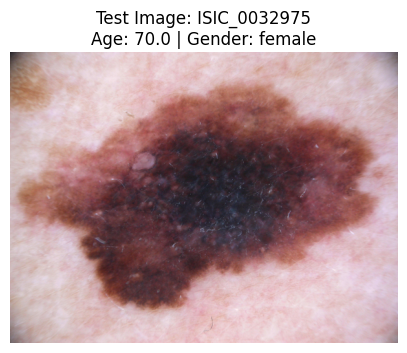

MULTIMODAL DENSENET121 PREDICTION

Input:
Image ID : ISIC_0032975
Age      : 70.0
Gender   : female

Actual:
Diagnosis: Malignant
Lesion   : mel

Predicted:
Diagnosis: Malignant
Binary Confidence: 96.49%
Lesion Type: mel
Lesion Confidence: 97.57%

Binary Probabilities:
Benign    : 3.51%
Malignant : 96.49%

Lesion Probabilities:
akiec     : 0.02%
bcc       : 0.01%
bkl       : 0.34%
df        : 0.00%
mel       : 97.57%
nv        : 2.07%
vasc      : 0.00%

✅ Binary diagnosis: CORRECT
✅ Lesion classification: CORRECT

⚠️ This is a machine-learning prediction
and not a clinical diagnosis.


In [42]:
# ============================================================
# MULTIMODAL DENSENET121 - FINAL IMAGE PREDICTION
# Image + Age + Gender
# ============================================================

from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


# ============================================================
# 1. TEST IMAGE INFORMATION
# ============================================================

image_id = "ISIC_0032975"

image_path = image_path_map[image_id]

age = 70.0
gender = "female"

actual_lesion = "mel"
actual_diagnosis = "Malignant"


# ============================================================
# 2. LOAD BEST MULTIMODAL DENSENET121
# ============================================================

checkpoint_dense = torch.load(
    best_model_path_dense,
    map_location=device
)

model_mm_dense.load_state_dict(
    checkpoint_dense["model_state_dict"]
)

model_mm_dense.to(device)
model_mm_dense.eval()


# ============================================================
# 3. LOAD IMAGE
# ============================================================

image = Image.open(image_path).convert("RGB")


# ============================================================
# 4. DISPLAY ORIGINAL IMAGE
# ============================================================

plt.figure(figsize=(5, 5))

plt.imshow(image)

plt.title(
    f"Test Image: {image_id}\n"
    f"Age: {age} | Gender: {gender}"
)

plt.axis("off")
plt.show()


# ============================================================
# 5. PREPARE IMAGE
# ============================================================

image_tensor = val_test_transform(image)

image_tensor = image_tensor.unsqueeze(0).to(device)


# ============================================================
# 6. PREPARE AGE AND GENDER
# ============================================================

age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender_mapping[gender]],
    dtype=torch.long
).to(device)


# ============================================================
# 7. MODEL PREDICTION
# ============================================================

with torch.no_grad():

    lesion_output, binary_output = model_mm_dense(
        image_tensor,
        age_tensor,
        gender_tensor
    )

    binary_probabilities = F.softmax(
        binary_output,
        dim=1
    )

    lesion_probabilities = F.softmax(
        lesion_output,
        dim=1
    )


# ============================================================
# 8. GET PREDICTIONS
# ============================================================

binary_prediction = torch.argmax(
    binary_probabilities,
    dim=1
).item()

lesion_prediction = torch.argmax(
    lesion_probabilities,
    dim=1
).item()


binary_names = [
    "Benign",
    "Malignant"
]

lesion_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]


# ============================================================
# 9. CONFIDENCE
# ============================================================

binary_confidence = (
    binary_probabilities[
        0,
        binary_prediction
    ].item() * 100
)

lesion_confidence = (
    lesion_probabilities[
        0,
        lesion_prediction
    ].item() * 100
)


predicted_diagnosis = binary_names[
    binary_prediction
]

predicted_lesion = lesion_names[
    lesion_prediction
]


# ============================================================
# 10. DISPLAY RESULTS
# ============================================================

print("=" * 60)
print("MULTIMODAL DENSENET121 PREDICTION")
print("=" * 60)

print("\nInput:")
print("Image ID :", image_id)
print("Age      :", age)
print("Gender   :", gender)

print("\nActual:")
print("Diagnosis:", actual_diagnosis)
print("Lesion   :", actual_lesion)

print("\nPredicted:")
print("Diagnosis:", predicted_diagnosis)
print(
    "Binary Confidence:",
    f"{binary_confidence:.2f}%"
)

print("Lesion Type:", predicted_lesion)
print(
    "Lesion Confidence:",
    f"{lesion_confidence:.2f}%"
)


# ============================================================
# 11. BINARY PROBABILITIES
# ============================================================

print("\nBinary Probabilities:")

for i, name in enumerate(binary_names):

    print(
        f"{name:10s}: "
        f"{binary_probabilities[0, i].item() * 100:.2f}%"
    )


# ============================================================
# 12. LESION PROBABILITIES
# ============================================================

print("\nLesion Probabilities:")

for i, name in enumerate(lesion_names):

    print(
        f"{name:10s}: "
        f"{lesion_probabilities[0, i].item() * 100:.2f}%"
    )


# ============================================================
# 13. CORRECTNESS CHECK
# ============================================================

print("\n" + "=" * 60)

if predicted_diagnosis == actual_diagnosis:
    print("✅ Binary diagnosis: CORRECT")
else:
    print("❌ Binary diagnosis: INCORRECT")


if predicted_lesion == actual_lesion:
    print("✅ Lesion classification: CORRECT")
else:
    print("❌ Lesion classification: INCORRECT")

print("=" * 60)

print("\n⚠️ This is a machine-learning prediction")
print("and not a clinical diagnosis.")

different age cancer ot not

AGE GROUP vs DIAGNOSIS
diagnosis  Benign  Malignant
age_group                   
0-20          404          8
21-40        2269        180
41-60        3708        647
61-80        1543        966
81+           137        153

Percentage distribution within each age group:
diagnosis  Benign  Malignant
age_group                   
0-20        98.06       1.94
21-40       92.65       7.35
41-60       85.14      14.86
61-80       61.50      38.50
81+         47.24      52.76


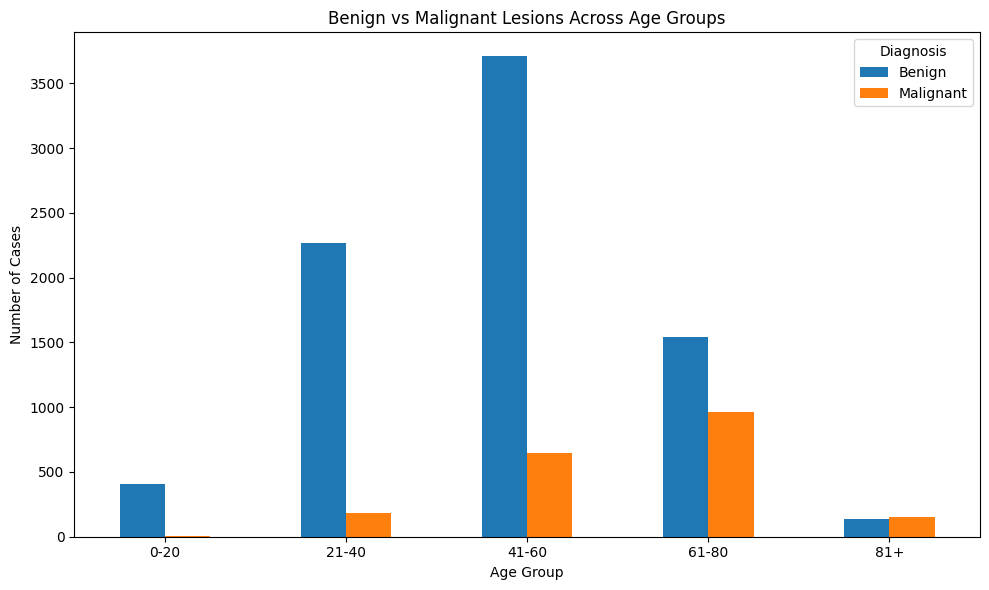

In [43]:
# ============================================================
# AGE ANALYSIS: BENIGN vs MALIGNANT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Make a copy of the original metadata
age_df = df.copy()

# Remove missing ages for this analysis
age_df = age_df.dropna(subset=["age"]).copy()

# Create age groups
age_df["age_group"] = pd.cut(
    age_df["age"],
    bins=[0, 20, 40, 60, 80, 100],
    labels=["0-20", "21-40", "41-60", "61-80", "81+"],
    include_lowest=True
)

# Convert binary label to diagnosis name
age_df["diagnosis"] = age_df["binary_label"].map({
    0: "Benign",
    1: "Malignant"
})

# Count cases
age_table = pd.crosstab(
    age_df["age_group"],
    age_df["diagnosis"]
)

print("=" * 60)
print("AGE GROUP vs DIAGNOSIS")
print("=" * 60)

print(age_table)

print("\nPercentage distribution within each age group:")

age_percentage = pd.crosstab(
    age_df["age_group"],
    age_df["diagnosis"],
    normalize="index"
) * 100

print(age_percentage.round(2))


# ============================================================
# PLOT
# ============================================================

age_table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Benign vs Malignant Lesions Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

Gender vs cancer or not

GENDER vs DIAGNOSIS
diagnosis  Benign  Malignant
gender                      
Female       3825        727
Male         4179       1227

Percentage distribution within each gender:
diagnosis  Benign  Malignant
gender                      
Female      84.03      15.97
Male        77.30      22.70


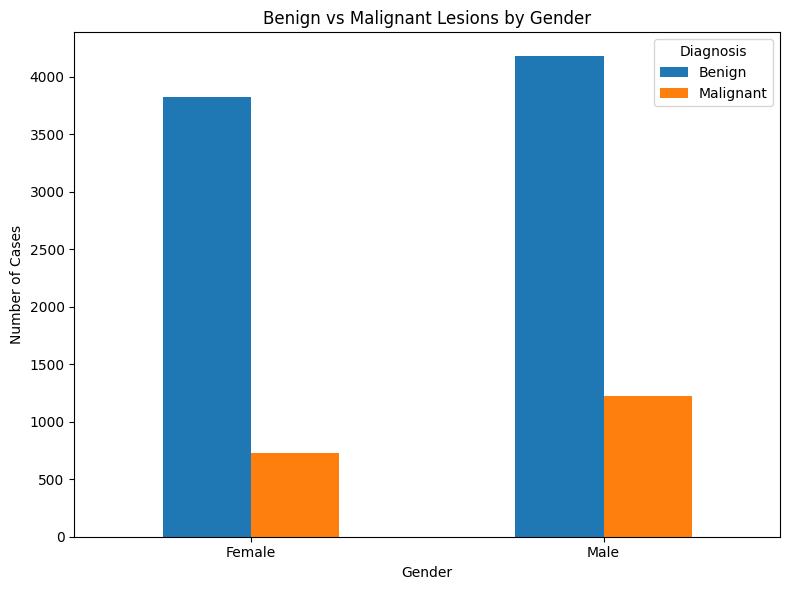

In [44]:
# ============================================================
# GENDER ANALYSIS: BENIGN vs MALIGNANT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Make a copy of the metadata
gender_df = df.copy()

# Convert gender codes to names
gender_df["gender"] = gender_df["sex"].map({
    "male": "Male",
    "female": "Female"
})

# Convert binary label to diagnosis
gender_df["diagnosis"] = gender_df["binary_label"].map({
    0: "Benign",
    1: "Malignant"
})

# Remove any unknown/missing gender values
gender_df = gender_df.dropna(subset=["gender"])

# Count cases
gender_table = pd.crosstab(
    gender_df["gender"],
    gender_df["diagnosis"]
)

print("=" * 60)
print("GENDER vs DIAGNOSIS")
print("=" * 60)

print(gender_table)

# Percentage distribution within each gender
print("\nPercentage distribution within each gender:")

gender_percentage = pd.crosstab(
    gender_df["gender"],
    gender_df["diagnosis"],
    normalize="index"
) * 100

print(gender_percentage.round(2))


# ============================================================
# PLOT
# ============================================================

gender_table.plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Benign vs Malignant Lesions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

prediction for external image multi model for both algorithms

In [45]:
# ============================================================
# EXTERNAL IMAGE PREDICTION
# Multimodal EfficientNet-B0 + Multimodal DenseNet121
# ============================================================

import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# ------------------------------------------------------------
# 1. UPLOAD IMAGE FROM LAPTOP
# ------------------------------------------------------------

print("\nSelect your skin lesion image:")

upload = widgets.FileUpload(
    accept='.jpg,.jpeg,.png,.avif',
    multiple=False
)

display(upload)

Device: cuda

Select your skin lesion image:


FileUpload(value=(), accept='.jpg,.jpeg,.png,.avif', description='Upload')

In [46]:
# ============================================================
# SAVE UPLOADED IMAGE + ENTER METADATA
# ============================================================

if not upload.value:
    raise ValueError("Please upload an image first.")

# Kaggle's FileUpload returns a tuple
uploaded_file = upload.value[0]

# Get filename
filename = uploaded_file["name"]

# Get image data
file_data = uploaded_file["content"]

# Save image
image_path = f"/kaggle/working/{filename}"

with open(image_path, "wb") as f:
    f.write(file_data)

print("Image uploaded successfully!")
print("Image path:", image_path)


# ------------------------------------------------------------
# ENTER AGE
# ------------------------------------------------------------

age_input = input(
    "\nEnter patient's age (or type 'unknown'): "
).strip()

if age_input.lower() == "unknown":
    age = 50.0
    print("Age unknown → using median age = 50")
else:
    age = float(age_input)


# ------------------------------------------------------------
# ENTER GENDER
# ------------------------------------------------------------

gender_input = input(
    "Enter gender (male / female / unknown): "
).strip().lower()

if gender_input not in ["male", "female", "unknown"]:
    raise ValueError(
        "Gender must be male, female, or unknown."
    )

gender_mapping = {
    "male": 0,
    "female": 1,
    "unknown": 2
}

gender_encoded = gender_mapping[gender_input]


# ------------------------------------------------------------
# DISPLAY IMAGE
# ------------------------------------------------------------

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("External Skin Lesion Image")
plt.show()


# ------------------------------------------------------------
# PREPROCESS IMAGE
# ------------------------------------------------------------

image_tensor = val_test_transform(
    image
).unsqueeze(0).to(device)

age_tensor = torch.tensor(
    [age / 100.0],
    dtype=torch.float32
).to(device)

gender_tensor = torch.tensor(
    [gender_encoded],
    dtype=torch.long
).to(device)

print("\nImage and metadata are ready for prediction.")

ValueError: Please upload an image first.

In [ ]:
# Check which multimodal model variables currently exist

print("EfficientNet variables:")
print([x for x in globals() if "eff" in x.lower()])

print("\nDenseNet variables:")
print([x for x in globals() if "dense" in x.lower()])

In [ ]:
# ============================================================
# CELL 57
# EXTERNAL IMAGE PREDICTION
# Using existing trained multimodal models
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# CLASS NAMES
# ------------------------------------------------------------

lesion_names = {
    0: "akiec",
    1: "bcc",
    2: "bkl",
    3: "df",
    4: "mel",
    5: "nv",
    6: "vasc"
}

binary_names = {
    0: "Benign",
    1: "Malignant"
}


# ------------------------------------------------------------
# PUT MODELS IN EVALUATION MODE
# ------------------------------------------------------------

model_mm_eff = model_mm_eff.to(device)
model_mm_dense = model_mm_dense.to(device)

model_mm_eff.eval()
model_mm_dense.eval()


# ------------------------------------------------------------
# PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_external(model, model_name):

    with torch.no_grad():

        lesion_output, binary_output = model(
            image_tensor,
            age_tensor,
            gender_tensor
        )

        # Binary probabilities
        binary_probs = F.softmax(
            binary_output,
            dim=1
        )[0]

        binary_class = torch.argmax(
            binary_probs
        ).item()

        binary_confidence = (
            binary_probs[binary_class].item() * 100
        )

        # Lesion probabilities
        lesion_probs = F.softmax(
            lesion_output,
            dim=1
        )[0]

        lesion_class = torch.argmax(
            lesion_probs
        ).item()

        lesion_confidence = (
            lesion_probs[lesion_class].item() * 100
        )


    # --------------------------------------------------------
    # DISPLAY RESULT
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(f"Age       : {age}")
    print(f"Gender    : {gender_input}")

    print("\nDiagnosis")
    print("-" * 30)

    print(
        f"{binary_names[binary_class]} "
        f"({binary_confidence:.2f}%)"
    )

    print("\nLesion Type")
    print("-" * 30)

    print(
        f"{lesion_names[lesion_class]} "
        f"({lesion_confidence:.2f}%)"
    )

    print("\nBinary Probabilities")
    print("-" * 30)

    print(
        f"Benign     : "
        f"{binary_probs[0].item()*100:.2f}%"
    )

    print(
        f"Malignant  : "
        f"{binary_probs[1].item()*100:.2f}%"
    )


    return {
        "diagnosis": binary_names[binary_class],
        "binary_confidence": binary_confidence,
        "lesion": lesion_names[lesion_class],
        "lesion_confidence": lesion_confidence
    }


# ------------------------------------------------------------
# EFFICIENTNET PREDICTION
# ------------------------------------------------------------

eff_result = predict_external(
    model_mm_eff,
    "MULTIMODAL EFFICIENTNET-B0"
)


# ------------------------------------------------------------
# DENSENET PREDICTION
# ------------------------------------------------------------

dense_result = predict_external(
    model_mm_dense,
    "MULTIMODAL DENSENET121"
)


# ------------------------------------------------------------
# FINAL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL COMPARISON")
print("=" * 60)

print("\nDiagnosis:")

print(
    f"EfficientNet-B0 : "
    f"{eff_result['diagnosis']} "
    f"({eff_result['binary_confidence']:.2f}%)"
)

print(
    f"DenseNet121     : "
    f"{dense_result['diagnosis']} "
    f"({dense_result['binary_confidence']:.2f}%)"
)

print("\nLesion Type:")

print(
    f"EfficientNet-B0 : "
    f"{eff_result['lesion']} "
    f"({eff_result['lesion_confidence']:.2f}%)"
)

print(
    f"DenseNet121     : "
    f"{dense_result['lesion']} "
    f"({dense_result['lesion_confidence']:.2f}%)"
)

print("\nModel Agreement:")

if eff_result["diagnosis"] == dense_result["diagnosis"]:
    print("✓ Both models agree on diagnosis.")
else:
    print("⚠ Models disagree on diagnosis.")

if eff_result["lesion"] == dense_result["lesion"]:
    print("✓ Both models agree on lesion type.")
else:
    print("⚠ Models disagree on lesion type.")